# Industry Crash-Risk Advisor
**Monthly industry-level risk monitoring and decision support**

**Who decides:** the portfolio manager or investor. The tool ranks 48 US industries by the risk of a severe drawdown and shows the evidence behind each signal. It does not trade, does not forecast when a drawdown will happen, and is not a source of extra return.

| | Function | What the user sees | Part |
|---|---|---|---|
| Core 1 | Industry Risk Ranking | Four relative risk levels with their historical severe-drawdown rate | 6 |
| Core 2 | Run-up Watch | Industries whose price has risen sharply, with the historical outcome of such run-ups | 7 |
| Core 3 | Portfolio Exposure Review | A portfolio's weight in each risk level and the holdings to review | 8 |
| Core 4 | Why This Industry Is Flagged | Contributing factors behind the ranking (not causes) | 9 |
| Support | Market Context | Volatility regime (HMM) and explosive price behaviour (GSADF) | 2, 3 |
| Support | Monthly Risk Report | All of the above for the latest month, with the data as-of date | 10 |

All model scores are out-of-sample: a model fitted at the end of year *Y−1* scores year *Y*. Part 11 reports what was tested and is **not** offered as a function, including the result that acting mechanically on the signal lowered returns.

# Part 0 — Setup

## 0.1 Libraries
* **Purpose:** Load the packages used in the notebook.
* **Method:** `hmmlearn`, `shap` and `xlrd` are not part of a default Colab runtime, so they are installed first.

In [1]:
%pip install -q hmmlearn shap xlrd

Note: you may need to restart the kernel to use updated packages.


In [2]:
import warnings
warnings.filterwarnings("ignore")
import io, os, zipfile
import numpy as np
import pandas as pd
from scipy import stats
from IPython.display import display

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import seaborn as sns

import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve
from hmmlearn.hmm import GaussianHMM
import shap

pd.set_option("display.max_columns", 40, "display.width", 250, "display.max_colwidth", None)

## 0.2 Settings
* **Purpose:** Keep every modelling choice in one place.
* **Method:** All settings are fixed before any result is seen. The Random Forest is the main model and the Logit is the simple benchmark; the choice is not revised after looking at test scores.

In [3]:
SEED, TRADING_DAYS = 42, 252
DATA_DIR, FIG_DIR  = "data", "figures"
MKT_NAME = "48-industry market"

# Target (Greenwood, Shleifer & You, 2019)
H_LIST    = [6, 12, 24]        # forecast horizons in months
MAIN_H    = 24                 # headline horizon
REL_DD    = 0.30               # Risk Ranking target: drawdown >= 30% of the industry price divided by the market, within H months
ABS_DD    = 0.40               # Run-up Watch target: drawdown >= 40% of the industry price itself (Greenwood et al.)
RUNUP_2Y, RUNUP_5Y = 1.00, 0.50   # run-up (Greenwood et al.): >= 100% in 2 years, raw and net of market, and >= 50% in 5 years
MIN_FIRMS = 10                 # an industry needs at least 10 firms
MASK_DD12 = -0.20              # "already falling": >= 20% below the 12-month high (not an early-warning month)

# Point-in-time availability of slow data
FRED_LAG, FRED_FFILL = 1, 2    # FRED month M is usable at the end of M+1, carried forward <= 2 months
CAPE_LAG, CAPE_FFILL = 3, 3    # Shiller CAPE earnings arrive about one quarter late
BM_MONTH = 12                  # BE/ME of year Y is usable from the end of December of year Y

# Layer 1: GSADF / PSY
PSY_W0, PSY_TB, N_SIM_PSY = 36, 24, 499  # minimum window, family-wise window (months), wild-bootstrap draws

# Layer 2: HMM
HMM_START, HMM_RT_START = "1950-01-01", 1955   # sample start, first year of point-in-time regimes
VOL_WINDOW = 21                                # days of realised volatility
REGIMES = ["Low volatility", "Normal volatility", "High volatility"]

# Layer 3: walk-forward
FIRST_TEST_YEAR  = 1960
STAGE1_TEST_YEAR = 1975        # first test year of the market-level model (needs the HMM and macro history)
MIN_TRAIN = 1000               # minimum training rows
HALF_LIFE_GRID = [10, 20, 40, np.inf]   # years; training rows are weighted by 0.5 ** (age / half-life); inf = no decay
VALID_YEARS    = range(1945, 1960)      # the half-life is chosen on these years only, before the test period starts
WINSOR    = (0.01, 0.99)       # continuous features are clipped to these training-set quantiles
MAIN_MODEL, BENCH_MODEL, VOL_MODEL = "RandomForest", "Logit", "Logit-Vol"
EXPLAIN_YEARS = {"Dot-com 2000": 1999, "GFC 2008": 2007, "COVID 2020": 2019, "Rates 2022": 2021}

# Evaluation, alerts and backtest
N_BOOT, BLOCK = 300, 24        # moving-block bootstrap: replications and block length (months)
LEVELS     = ["Low", "Normal", "Elevated", "High"]   # quartiles of the monthly ranking, fixed in advance
RUNUP_GRID = [0.50, 0.75, 1.00, 1.25, 1.50]          # run-up thresholds reported in 7.2; 100% is the pre-specified one
ALERT_K    = 5                 # the 5 highest-ranked industries each month (used in the research tests of Part 11)
COST_BPS   = 10                # trading cost per unit of traded value

REGIME_COLORS = dict(zip(REGIMES, ["#1baf7a", "#eda100", "#e34948"]))
MODEL_COLORS  = {"Logit-Vol": "#9a9994", "Logit": "#2a78d6", "RandomForest": "#eb6834"}
os.makedirs(FIG_DIR, exist_ok=True)

def save(fig, name):
    fig.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=200, bbox_inches="tight")
    plt.show()

# Part 1 — Data

## 1.1 Load the local data files
* **Purpose:** Read all inputs from the `data/` folder. Nothing is fetched from the web, so every run uses the same snapshot.
* **Setup:** The notebook expects the `data/` folder next to it. In Colab, where only the notebook is open, drag `data.zip` into the Files panel before running; it is unpacked into `data/`. If no `data.zip` is found, the cell asks for an upload instead.
* **Method:** Ken French files hold several tables in one CSV; they are split on blank lines and −99.99 / −999 is treated as missing. Returns are value-weighted total returns, the equivalent of adjusted prices.

| File | Content | Source |
|---|---|---|
| `49_Industry_Portfolios_CSV.zip` | Monthly returns, firm counts, firm size, BE/ME | Ken French Data Library |
| `49_Industry_Portfolios_daily_CSV.zip` | Daily returns | Ken French Data Library |
| `F-F_Research_Data_Factors_CSV.zip` | Mkt-RF, SMB, HML, RF | Ken French Data Library |
| `BAA`, `AAA`, `GS10`, `TB3MS`, `USREC` `.csv` | Corporate yields, Treasury yields, NBER recessions | FRED |
| `ie_data.xls` | Shiller CAPE | shillerdata.com |

In [4]:
DATA_FILES = ["49_Industry_Portfolios_CSV.zip", "49_Industry_Portfolios_daily_CSV.zip", "F-F_Research_Data_Factors_CSV.zip",
              "BAA.csv", "AAA.csv", "GS10.csv", "TB3MS.csv", "USREC.csv", "ie_data.xls"]

def ensure_data():
    """Make sure every data file is in DATA_DIR. Sources, in order: data.zip next to the notebook, then a Colab upload."""
    missing = lambda: [f for f in DATA_FILES if not os.path.exists(os.path.join(DATA_DIR, f))]
    def unpack(archive):                                            # keep only the expected files, whatever the folder inside
        with zipfile.ZipFile(archive) as z:
            for member in z.namelist():
                if os.path.basename(member) in DATA_FILES:
                    open(os.path.join(DATA_DIR, os.path.basename(member)), "wb").write(z.read(member))
    if not missing():
        return
    os.makedirs(DATA_DIR, exist_ok=True)
    if os.path.exists("data.zip"):
        unpack("data.zip")
    if missing():
        try:
            from google.colab import files
        except ImportError:
            raise FileNotFoundError(f"Missing in '{DATA_DIR}/': {missing()}. Put data.zip or the data folder next to the notebook.")
        for name, content in files.upload().items():                # choose data.zip, or the data files themselves
            if name in DATA_FILES:
                open(os.path.join(DATA_DIR, name), "wb").write(content)
            elif name.lower().endswith(".zip"):
                unpack(io.BytesIO(content))
    assert not missing(), f"Still missing: {missing()}"

ensure_data()

def read_french(fname):
    with zipfile.ZipFile(os.path.join(DATA_DIR, fname)) as z:
        text = z.read(z.namelist()[0]).decode("latin-1").replace("\r", "")
    tables = {}
    for block in text.split("\n\n"):
        lines = block.strip("\n").split("\n")
        h = next((i for i, l in enumerate(lines) if l.startswith(",")), None)   # header row ",col1,col2,..."
        if h is None:
            continue
        df = pd.read_csv(io.StringIO("\n".join(lines[h:])), index_col=0, float_precision="round_trip")
        df.columns = df.columns.str.strip()
        df = df.mask(df <= -99.99)
        idx = df.index.astype(str).str.strip()
        if len(idx[0]) == 6:
            df.index = pd.to_datetime(idx, format="%Y%m") + pd.offsets.MonthEnd(0)
        elif len(idx[0]) == 8:
            df.index = pd.to_datetime(idx, format="%Y%m%d")
        tables[lines[h - 1].strip() if h else ""] = df
    return tables

def read_fred(sid):
    s = pd.read_csv(os.path.join(DATA_DIR, f"{sid}.csv"), index_col=0, parse_dates=True, na_values=".").iloc[:, 0]
    s = s.astype(float).dropna()
    s.index = s.index + pd.offsets.MonthEnd(0)
    return s.rename(sid)

def read_cape():
    x = pd.read_excel(os.path.join(DATA_DIR, "ie_data.xls"), sheet_name="Data", skiprows=7)[["Date", "CAPE"]]
    x = x.apply(pd.to_numeric, errors="coerce").dropna()
    year = x["Date"].astype(int)
    month = ((x["Date"] - year) * 100).round().astype(int)          # 2024.1 = October
    idx = pd.to_datetime(dict(year=year, month=month, day=1)) + pd.offsets.MonthEnd(0)
    return pd.Series(x["CAPE"].values, index=idx, name="CAPE")

ind_tables = read_french("49_Industry_Portfolios_CSV.zip")
day_tables = read_french("49_Industry_Portfolios_daily_CSV.zip")
ff   = next(iter(read_french("F-F_Research_Data_Factors_CSV.zip").values())) / 100   # first table = monthly factors
fred = {sid: read_fred(sid) for sid in ["BAA", "AAA", "GS10", "TB3MS", "USREC"]}
cape = read_cape()

drop_other = lambda t: t.drop(columns="Other")                      # 49 portfolios minus "Other" = 48 industries
ret    = drop_other(ind_tables["Average Value Weighted Returns -- Monthly"]) / 100
ret_ew = drop_other(ind_tables["Average Equal Weighted Returns -- Monthly"]) / 100
nfirms = drop_other(ind_tables["Number of Firms in Portfolios"]).reindex(ret.index)
fsize  = drop_other(ind_tables["Average Firm Size"]).reindex(ret.index)
be_me  = drop_other(ind_tables["Sum of BE / Sum of ME"])
dret   = drop_other(day_tables["Average Value Weighted Returns -- Daily"]) / 100
mkt    = (ff["Mkt-RF"] + ff["RF"]).reindex(ret.index)               # Fama-French market, total return
mcap   = nfirms * fsize                                             # industry market cap ($ million)
INDS   = list(ret.columns)

## 1.2 Market index, sectors and the common end date
* **Purpose:** Build a daily market index and 11 GICS-like sectors from the 48 industries, then cut every series at one end date.
* **Method:** Weights are last month's market cap, so they are known before the return is earned. An industry without a return on a given day gets no weight, which avoids artificial 0% returns. The end date is the last month with complete daily data.

In [5]:
GICS_MAP = {
    "Energy":                 ["Coal", "Oil"],
    "Materials":              ["Chems", "Rubbr", "BldMt", "Steel", "Gold", "Mines", "Paper", "Boxes"],
    "Industrials":            ["Cnstr", "FabPr", "Mach", "ElcEq", "Aero", "Ships", "Guns", "BusSv", "Trans", "Whlsl"],
    "Consumer Discretionary": ["Toys", "Clths", "Txtls", "Autos", "PerSv", "Rtail", "Meals"],
    "Consumer Staples":       ["Agric", "Food", "Soda", "Beer", "Smoke", "Hshld"],
    "Health Care":            ["Hlth", "MedEq", "Drugs"],
    "Financials":             ["Banks", "Insur", "Fin"],
    "Information Technology": ["Hardw", "Softw", "Chips", "LabEq"],
    "Communication Services": ["Telcm", "Fun", "Books"],
    "Utilities":              ["Util"],
    "Real Estate":            ["RlEst"],
}
SECTOR_OF = {ind: sec for sec, inds in GICS_MAP.items() for ind in inds}
assert set(INDS) == set(SECTOR_OF), "every industry needs exactly one sector"

w_prev = mcap.shift(1)                                              # market cap at the end of the previous month
w_d = w_prev.set_axis(w_prev.index.to_period("M")).reindex(dret.index.to_period("M")).set_axis(dret.index).where(dret.notna())
mkt_daily = (1 + (dret * w_d).sum(axis=1, min_count=1) / w_d.sum(axis=1, min_count=1)).dropna().cumprod()
sector_ret = pd.DataFrame({sec: (ret[c] * w_prev[c]).sum(axis=1, min_count=1) / w_prev[c].where(ret[c].notna()).sum(axis=1)
                           for sec, c in GICS_MAP.items()}).dropna(how="all")

last_day   = mkt_daily.index[-1]
month_done = (last_day + pd.offsets.BDay(1)).month != last_day.month
END = min(ret.index[-1], last_day + pd.offsets.MonthEnd(0) if month_done else last_day - pd.offsets.MonthEnd(1))
ret, ret_ew, nfirms, mcap, mkt, sector_ret, dret, mkt_daily = [
    x.loc[:END] for x in (ret, ret_ew, nfirms, mcap, mkt, sector_ret, dret, mkt_daily)]
mkt_m     = mkt_daily.resample("ME").last()                         # month-end index level
mkt_ret_d = np.log(mkt_daily).diff().dropna()                       # daily log return on the trading calendar itself
usrec     = fred["USREC"].loc[:END]                                 # NBER recessions: shading and validation only
RF_M      = ff["RF"]                                                # monthly T-bill return

## 1.3 Data quality checks
* **Purpose:** Confirm that the inputs are sorted, unique and plausible before any modelling.
* **Method:** One row per series with its date range, row count and share of missing values. The constructed index is compared with the Fama-French market, and the share of zero daily returns is reported as a stale-price check.

In [6]:
series = {"ret (monthly)": ret, "ret_ew (monthly)": ret_ew, "dret (daily)": dret, "sector_ret": sector_ret,
          "nfirms": nfirms, "be_me (annual)": be_me, "mkt_daily": mkt_daily, **fred, "CAPE": cape}
for name, x in series.items():
    assert x.index.is_monotonic_increasing and not x.index.has_duplicates, f"{name}: dates must be sorted and unique"
quality = pd.DataFrame({name: {"Start": str(x.index[0])[:10], "End": str(x.index[-1])[:10], "Rows": len(x),
                               "Missing %": 100 * np.isnan(np.asarray(x, dtype=float)).mean()}
                        for name, x in series.items()}).T.astype({"Rows": int, "Missing %": float}).round(2)

chk = pd.concat({"MKT48": mkt_m.pct_change(), "FF": mkt}, axis=1).dropna()
index_check = pd.Series({"Common end date": f"{END:%Y-%m-%d}", "Industries": len(INDS),
                         "Correlation with FF market (monthly)": round(chk.corr().iloc[0, 1], 4),
                         "Mean abs. difference per month (%)": round(100 * (chk["MKT48"] - chk["FF"]).abs().mean(), 3),
                         "Zero daily index returns (%)": round(100 * (mkt_ret_d == 0).mean(), 2),
                         "Industry-months with |return| > 50% (kept)": int((ret.abs() > 0.5).sum().sum())}, name="Value")
display(quality, index_check.to_frame())

,Start,End,Rows,Missing %
ret (monthly),1926-07-31,2026-09-30,1203,4.97
ret_ew (monthly),1926-07-31,2026-09-30,1203,4.97
dret (daily),1926-07-01,2026-09-30,26338,5.32
sector_ret,1926-08-31,2026-09-30,1202,0.00
nfirms,1926-07-31,2026-09-30,1203,0.00
be_me (annual),1926,2026,101,5.07
mkt_daily,1926-08-02,2026-09-30,26313,0.00
BAA,1919-01-31,2026-10-31,1294,0.00
AAA,1919-01-31,2026-10-31,1294,0.00
GS10,1953-04-30,2026-10-31,883,0.00


,Value
Common end date,2026-09-30
Industries,48
Correlation with FF market (monthly),0.9994
Mean abs. difference per month (%),0.095
Zero daily index returns (%),0.0
Industry-months with |return| > 50% (kept),66


## 1.4 Return summary by sector
* **Purpose:** Show how different the sectors are and how fat-tailed monthly returns are.
* **Method:** Monthly statistics; volatility is annualised with √12. Kurtosis is **excess** kurtosis (normal = 0). Fat tails are the reason crashes are defined from observed drawdowns and skill is judged with rank-based metrics.

In [7]:
def return_summary(r):
    r = r.dropna()
    return pd.Series({"Months": len(r), "Mean %/month": r.mean() * 100, "Ann. vol % (x sqrt12)": r.std() * np.sqrt(12) * 100,
                      "Skew": stats.skew(r), "Excess kurtosis": stats.kurtosis(r), "Min %": r.min() * 100, "Max %": r.max() * 100})

eda = pd.DataFrame({s: return_summary(sector_ret[s]) for s in sector_ret}).T
eda.loc[MKT_NAME] = return_summary(mkt_m.pct_change())
eda.round(2).astype({"Months": int})

,Months,Mean %/month,Ann. vol % (x sqrt12),Skew,Excess kurtosis,Min %,Max %
Energy,1202,1.04,22.27,0.23,4.22,-34.67,39.37
Materials,1202,0.97,21.96,0.69,9.63,-29.06,55.54
Industrials,1202,1.00,22.97,0.64,10.67,-31.78,56.60
Consumer Discretionary,1202,1.06,21.60,0.47,9.54,-31.35,58.54
Consumer Staples,1202,0.93,15.92,-0.05,6.55,-27.34,35.32
Health Care,1202,1.07,19.05,0.08,6.63,-34.76,37.33
Financials,1202,1.02,23.42,0.44,11.32,-40.47,59.44
Information Technology,1202,1.21,22.70,-0.22,2.56,-32.11,33.50
Communication Services,1202,0.82,16.37,-0.14,2.88,-23.02,29.26
Utilities,1202,0.87,18.82,0.11,7.48,-29.72,43.55


# Part 2 — Market context: explosive price behaviour (GSADF)

## 2.1 PSY test functions
* **Purpose:** Date explosive price behaviour point in time, using only data up to each month (Phillips, Shi & Yu, 2015).
* **Method:** BSADF at month *t* is the largest ADF statistic over all windows that end at *t*, so it uses data up to *t* only. Critical values come from a wild bootstrap. A month is flagged when BSADF exceeds the 95% critical value and the 12-month price change is positive. `Margin` = BSADF − critical value keeps the strength of the signal, not only the 0/1 flag.

In [8]:
def bsadf_matrix(Y, w0=PSY_W0):
    # Y: (n_series, T) log prices without NaN. ADF regression: dy_t = a + rho * y_{t-1} + e_t (lag 0)
    S, T = Y.shape
    x, z = Y[:, :-1], np.diff(Y, axis=1)
    csum = lambda a: np.concatenate([np.zeros((S, 1)), np.cumsum(a, axis=1)], axis=1)
    Sx, Sz, Sxx, Szz, Sxz = csum(x), csum(z), csum(x * x), csum(z * z), csum(x * z)
    out = np.full((S, T), np.nan)
    for j in range(w0 - 1, T - 1):
        s = np.arange(0, j - w0 + 2)                                # every admissible window start
        n = (j + 1 - s).astype(float)
        sx, sz = Sx[:, [j + 1]] - Sx[:, s], Sz[:, [j + 1]] - Sz[:, s]
        sxx, szz, sxz = Sxx[:, [j + 1]] - Sxx[:, s], Szz[:, [j + 1]] - Szz[:, s], Sxz[:, [j + 1]] - Sxz[:, s]
        vxx = np.maximum(sxx - sx * sx / n, 1e-12)
        cxz = sxz - sx * sz / n
        rho = cxz / vxx
        ssr = np.maximum((szz - sz * sz / n) - rho * cxz, 1e-12)
        out[:, j + 1] = np.max(rho / np.sqrt(ssr / (n - 2) / vxx), axis=1)
    return out

def run_psy(price, seed=SEED):
    """Point-in-time PSY for one price series. Returns the monthly table and the full-sample GSADF test (ex-post)."""
    logp = np.log(price.dropna())
    y = logp.values - logp.values[0]
    d = np.diff(y)
    e = d - np.cumsum(d) / np.arange(1, len(d) + 1)                 # residual under H0, expanding mean
    g = np.random.default_rng(seed).standard_normal((len(d), N_SIM_PSY)).T
    sims = np.concatenate([np.zeros((N_SIM_PSY, 1)), np.cumsum(e * g, axis=1)], axis=1)
    b = bsadf_matrix(np.vstack([y, sims]))
    sim_max = pd.DataFrame(b[1:].T).rolling(PSY_TB, min_periods=1).max().values.T
    with np.errstate(all="ignore"):
        cv = np.nanquantile(sim_max, 0.95, axis=0)
    out = pd.DataFrame({"BSADF": b[0], "CV": cv}, index=logp.index)
    out["Margin"] = out["BSADF"] - out["CV"]
    out["Bubble"] = ((out["Margin"] > 0) & (logp.diff(12) > 0)).astype(float).where(out["CV"].notna())
    g_stat, sim_g = np.nanmax(b[0]), np.nanmax(b[1:], axis=1)
    gsadf = {"GSADF": g_stat, "CV 95%": np.quantile(sim_g, 0.95), "p-value": (1 + (sim_g >= g_stat).sum()) / (1 + len(sim_g))}
    return out, gsadf

def run_psy_returns(r, seed=SEED):
    """PSY on each continuous run of monthly returns; after a data gap the test starts again, as it would in real time."""
    parts, best = [], (0, None)
    for _, seg in r.dropna().groupby(r.isna().cumsum()[r.notna()]):
        if len(seg) <= PSY_W0 + PSY_TB:
            continue
        base = pd.Series([1.0], index=[seg.index[0] - pd.offsets.MonthEnd(1)])
        res, g = run_psy(pd.concat([base, (1 + seg).cumprod()]), seed=seed)
        parts.append(res)
        if len(seg) > best[0]:
            best = (len(seg), g)
    return pd.concat(parts).reindex(r.index), best[1]

def episodes(flag, min_len=3):
    """Runs of at least `min_len` flagged months: Start, Detected (month the run is confirmed), End, Months."""
    f = flag.fillna(0).astype(bool)
    rows = [(g.index[0], g.index[min_len - 1], g.index[-1], len(g))
            for _, g in f.groupby((f != f.shift()).cumsum()) if g.iloc[0] and len(g) >= min_len]
    return pd.DataFrame(rows, columns=["Start", "Detected", "End", "Months"])

## 2.2 GSADF test: market and 11 sectors
* **Purpose:** Test whether explosive episodes exist and check that well-known bubbles are flagged.
* **Method:** The GSADF statistic is a full-sample, ex-post test against its 95% bootstrap critical value (499 draws). The monthly flags, each computed from data up to that month, are the monitoring signal. The sector tests are not adjusted for testing 11 series. The second table shows how many months of four well-known episodes were flagged; a low share means the test missed that episode.

In [9]:
mkt_psy, mkt_gsadf = run_psy(mkt_m)
sector_px  = (1 + sector_ret).cumprod()
sector_psy, rows = {}, [{"Series": MKT_NAME, **mkt_gsadf, "Bubble months": int(mkt_psy["Bubble"].sum()),
                         "Episodes": len(episodes(mkt_psy["Bubble"]))}]
for i, sec in enumerate(GICS_MAP):
    sector_psy[sec], g = run_psy_returns(sector_ret[sec], seed=SEED + i)
    rows.append({"Series": sec, **g, "Bubble months": int(sector_psy[sec]["Bubble"].sum()),
                 "Episodes": len(episodes(sector_psy[sec]["Bubble"]))})
gsadf_table = pd.DataFrame(rows).set_index("Series")
gsadf_table["Reject H0 (5%)"] = gsadf_table["GSADF"] > gsadf_table["CV 95%"]

KNOWN = [("Dot-com", MKT_NAME, "1995-01", "2000-08"), ("Dot-com", "Information Technology", "1997-01", "2000-08"),
         ("Oil boom", "Energy", "2004-01", "2008-07"), ("Late-90s financials", "Financials", "1995-01", "1998-07")]
psy_of = {MKT_NAME: mkt_psy, **sector_psy}
known_check = pd.DataFrame([{"Episode": lab, "Series": name, "Window": f"{a} to {b}",
                             "Months flagged": int(psy_of[name]["Bubble"].loc[a:b].sum()),
                             "Share flagged": psy_of[name]["Bubble"].loc[a:b].mean()} for lab, name, a, b in KNOWN])
display(gsadf_table.round(3), known_check.round(2))

,GSADF,CV 95%,p-value,Bubble months,Episodes,Reject H0 (5%)
Series,,,,,,
48-industry market,2.389,4.337,0.566,119,11,False
Energy,2.913,4.019,0.262,42,6,False
Materials,2.505,4.048,0.430,47,8,False
Industrials,3.825,4.236,0.104,29,3,False
Consumer Discretionary,2.270,3.731,0.550,44,7,False
Consumer Staples,3.769,4.220,0.106,240,15,False
Health Care,3.343,4.279,0.168,145,8,False
Financials,4.069,4.324,0.086,118,10,False
Information Technology,2.766,4.341,0.376,120,12,False


,Episode,Series,Window,Months flagged,Share flagged
0,Dot-com,48-industry market,1995-01 to 2000-08,13,0.19
1,Dot-com,Information Technology,1997-01 to 2000-08,6,0.14
2,Oil boom,Energy,2004-01 to 2008-07,2,0.04
3,Late-90s financials,Financials,1995-01 to 1998-07,24,0.56


## 2.3 Chart: point-in-time bubble flags
* **Purpose:** Show where and when prices rose explosively.
* **Method:** Index level on a log axis. Red shading marks episodes flagged for at least 3 months; grey marks NBER recessions on the market panel. Sectors are sorted by the share of months flagged.

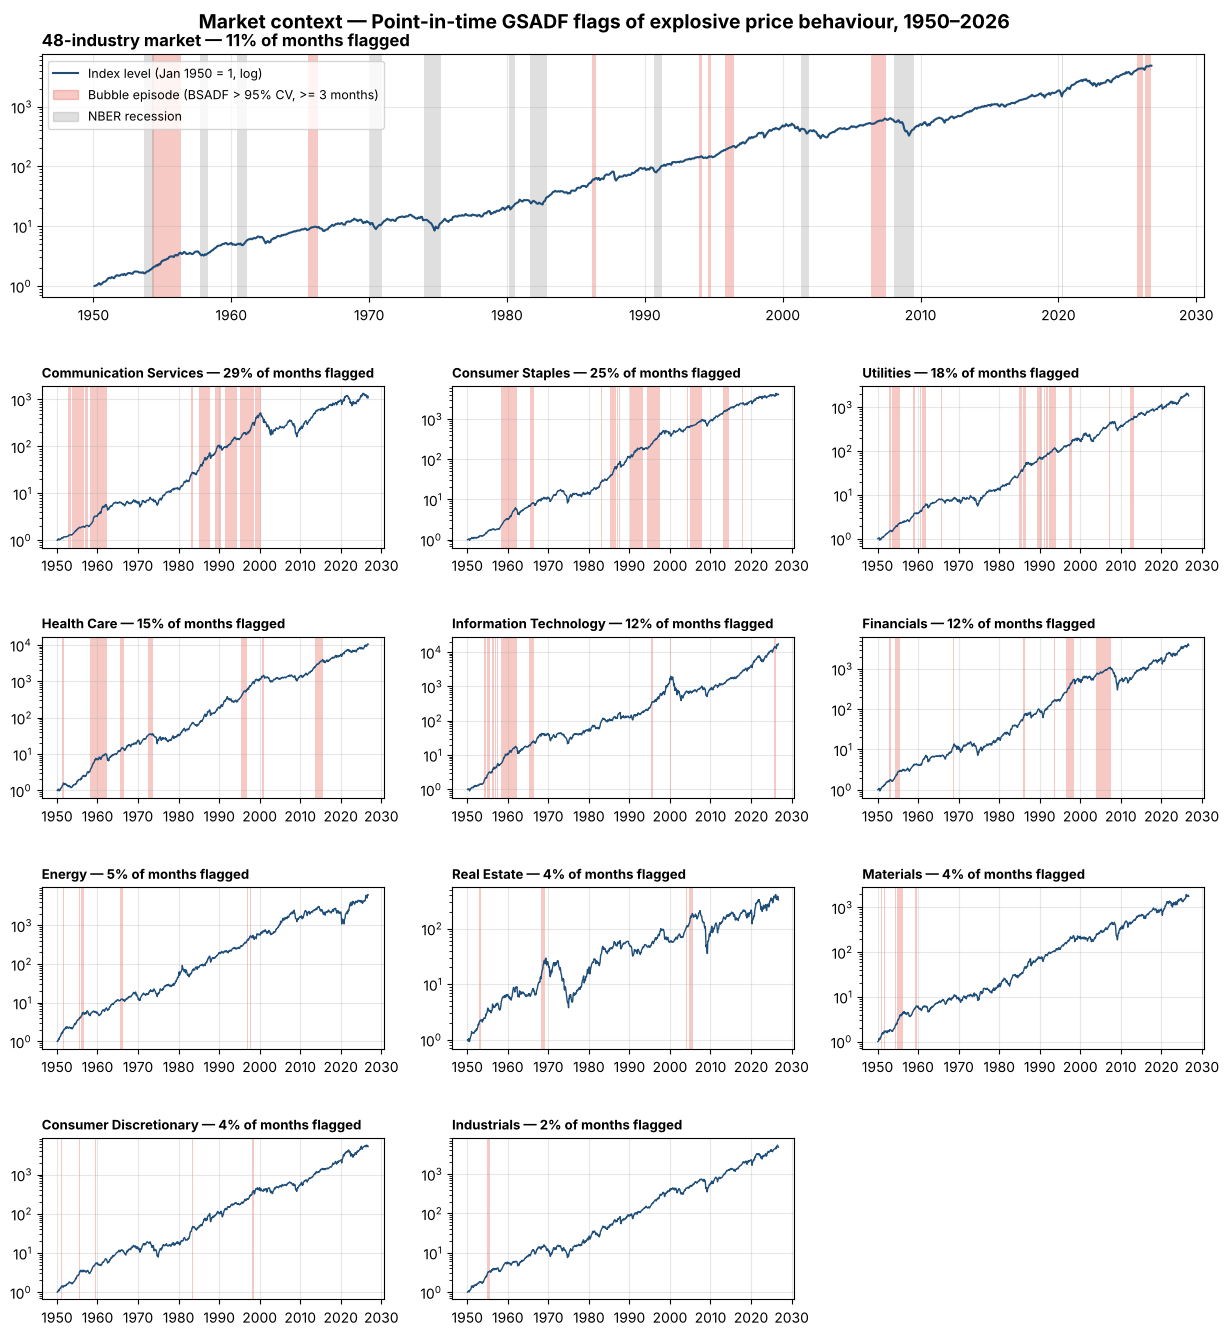

In [10]:
PLOT_START = "1950-01-01"
order  = sorted(GICS_MAP, key=lambda s: -sector_psy[s]["Bubble"].loc[PLOT_START:END].mean())
panels = [(MKT_NAME, mkt_m, mkt_psy)] + [(sec, sector_px[sec], sector_psy[sec]) for sec in order]

fig = plt.figure(figsize=(15, 15))
gs = fig.add_gridspec(5, 3, height_ratios=[1.5, 1, 1, 1, 1], hspace=0.5, wspace=0.2, top=0.94)
fig.suptitle(f"Market context — Point-in-time GSADF flags of explosive price behaviour, 1950–{END:%Y}", fontsize=14, fontweight="bold", y=0.97)
for k, (name, px, sig) in enumerate(panels):
    ax = fig.add_subplot(gs[0, :] if k == 0 else gs[1 + (k - 1) // 3, (k - 1) % 3])
    px, sig = px.loc[PLOT_START:END], sig.loc[PLOT_START:END]
    ax.plot(px.index, px / px.iloc[0], color="#1f4e79", lw=1.5 if k == 0 else 1)
    for _, ep in episodes(sig["Bubble"]).iterrows():
        ax.axvspan(ep["Start"] - pd.offsets.MonthBegin(1), ep["End"], color="#e74c3c", alpha=0.3, lw=0)
    if k == 0:
        rec = usrec.loc[PLOT_START:].eq(1)
        ax.fill_between(rec.index, 0, 1, where=rec.values, step="pre", color="gray", alpha=0.25, lw=0,
                        transform=ax.get_xaxis_transform())
        ax.legend(handles=[Line2D([], [], color="#1f4e79", label="Index level (Jan 1950 = 1, log)"),
                           Patch(color="#e74c3c", alpha=0.3, label="Bubble episode (BSADF > 95% CV, >= 3 months)"),
                           Patch(color="gray", alpha=0.25, label="NBER recession")], loc="upper left", fontsize=9)
    ax.set_yscale("log")
    ax.set_title(f"{name} — {sig['Bubble'].mean():.0%} of months flagged", loc="left",
                 fontsize=12 if k == 0 else 9.5, fontweight="bold")
    ax.grid(True, alpha=0.3)
save(fig, "layer1_gsadf_bubbles")

## 2.4 PSY signal for the 48 industries
* **Purpose:** Produce the industry-level bubble flag and the continuous signal strength used later as model inputs.
* **Method:** PSY is run on each industry's return history. Months with fewer than 10 firms are set to missing.

In [11]:
ind_psy    = pd.DataFrame(index=ret.index, columns=INDS, dtype=float)   # 0/1 flag
ind_margin = ind_psy.copy()                                             # BSADF - critical value
for i, ind in enumerate(INDS):
    res, _ = run_psy_returns(ret[ind], seed=SEED + 100 + i)
    ind_psy[ind], ind_margin[ind] = res["Bubble"], res["Margin"]
too_few = nfirms < MIN_FIRMS
ind_psy, ind_margin = ind_psy.mask(too_few), ind_margin.mask(too_few)
pd.Series({"Industry-months with a PSY result": int(ind_psy.notna().sum().sum()),
           "Share flagged as bubble": round(ind_psy.stack().mean(), 4),
           "Industries with a data gap (PSY restarted)": int(((ret.notna() & ret.shift().isna()).sum() > 1).sum())},
          name="Value", dtype=object).to_frame()

,Value
Industry-months with a PSY result,42022
Share flagged as bubble,0.0644
Industries with a data gap (PSY restarted),1


## 2.5 Look-ahead test for Layer 1
* **Purpose:** Prove that the flag at month *t* does not use data after *t*.
* **Method:** Truncation test. PSY is rerun on data cut at a past date; every value up to that date must equal the full-sample run.

In [12]:
rows = []
for name, price, cuts, seed in [(MKT_NAME, mkt_m, ["1987-09-30", "1999-12-31", "2019-12-31"], SEED),
                                ("Information Technology", sector_px["Information Technology"], ["1999-12-31"], SEED + 7)]:
    full, _ = run_psy(price, seed=seed)
    for cut in cuts:
        part, _ = run_psy(price.loc[:cut], seed=seed)
        same = np.allclose(full.loc[part.index], part, equal_nan=True)
        assert same, f"look-ahead in PSY at {cut}"
        rows.append({"Series": name, "Cut date": cut, "Months compared": len(part), "Identical": same})
pd.DataFrame(rows)

,Series,Cut date,Months compared,Identical
0,48-industry market,1987-09-30,734,True
1,48-industry market,1999-12-31,881,True
2,48-industry market,2019-12-31,1121,True
3,Information Technology,1999-12-31,881,True


# Part 3 — Market context: volatility regime (HMM)

## 3.1 HMM functions
* **Purpose:** Classify each day into a Low-, Normal- or High-volatility market regime using past data only.
* **Method:** A 3-state Gaussian HMM on two inputs: the daily log return and the log of 21-day realised volatility (annualised with √252). The scaler and the model are refitted at each year end and then **forward-filtered** over the next year. `predict_proba` of `hmmlearn` is not used because it is smoothed with future data. States are named by sorting on fitted volatility, so labels cannot switch between fits.

In [13]:
hmm_df = pd.DataFrame({"Return": mkt_ret_d})
hmm_df["Log_Vol"] = np.log(hmm_df["Return"].rolling(VOL_WINDOW).std() * np.sqrt(TRADING_DAYS))
warmup = int(hmm_df.loc[HMM_START:END, "Log_Vol"].isna().sum())     # rows lost to the rolling window (reported in 3.2)
hmm_df = hmm_df.loc[HMM_START:END].dropna()
VOL_COL = 1

def fit_hmm(X, K=3, seeds=(0,), init=None):
    """Highest log-likelihood over random starts, plus a warm start from last year's model."""
    cands = []
    if init is not None:
        m = GaussianHMM(n_components=K, covariance_type="full", n_iter=200, tol=1e-4, random_state=0, init_params="")
        m.startprob_, m.transmat_ = init.startprob_.copy(), init.transmat_.copy()
        m.means_, m.covars_ = init.means_.copy(), init.covars_.copy()
        cands.append(m)
    cands += [GaussianHMM(n_components=K, covariance_type="full", n_iter=200, tol=1e-4, random_state=s) for s in seeds]
    best, best_ll = None, -np.inf
    for m in cands:
        try:
            ll = m.fit(X).score(X)
        except Exception:
            continue
        if np.isfinite(ll) and ll > best_ll:
            best, best_ll = m, ll
    return best

def hmm_filter(model, X):
    """Forward filter: P(state_t | data up to t)."""
    K = model.n_components
    log_b = np.column_stack([stats.multivariate_normal(model.means_[k], model.covars_[k], allow_singular=True).logpdf(X)
                             for k in range(K)])
    alpha = np.zeros((len(X), K))
    a = model.startprob_ * np.exp(log_b[0] - log_b[0].max())
    alpha[0] = a / a.sum()
    for t in range(1, len(X)):
        a = (alpha[t - 1] @ model.transmat_) * np.exp(log_b[t] - log_b[t].max())
        alpha[t] = a / a.sum() if a.sum() > 0 else alpha[t - 1] @ model.transmat_
    return alpha

def hmm_realtime(df, cache=None):
    """Scaler and model fitted at 31 Dec of year Y-1, forward-filtered over year Y. `cache` reuses earlier fits."""
    out, models, prev = [], {}, None
    for y in range(HMM_RT_START, df.index[-1].year + 1):
        fit_end = pd.Timestamp(f"{y - 1}-12-31")
        if cache and fit_end in cache:
            m, sc, o = cache[fit_end]
        else:
            train = df.loc[:fit_end]
            sc = StandardScaler().fit(train)                        # scaler sees the training window only
            m = fit_hmm(sc.transform(train), init=prev)
            o = np.argsort(m.means_[:, VOL_COL])                    # Low < Normal < High volatility
        models[fit_end], prev = (m, sc, o), m
        hist = df.loc[:f"{y}-12-31"]
        p = hmm_filter(m, sc.transform(hist))[:, o]
        out.append(pd.DataFrame(p, index=hist.index, columns=REGIMES).loc[f"{y}":])
    filt = pd.concat(out)
    return filt, filt.idxmax(axis=1), models

## 3.2 Point-in-time regimes
* **Purpose:** Run the walk-forward HMM and describe the three regimes.
* **Method:** One fit per year from 1955. The table gives the share of days in each regime and the fitted volatility of each state, averaged over all fits. The names describe volatility relative to the other two states only; "High" is not an extreme state. Asserts check that probabilities sum to 1 and that the volatility ordering holds in every fit.

In [14]:
filt, regime, hmm_rt_models = hmm_realtime(hmm_df)
fit_vol = pd.DataFrame({fd: 100 * np.exp(sc.inverse_transform(m.means_[o])[:, VOL_COL])
                        for fd, (m, sc, o) in hmm_rt_models.items()}, index=REGIMES).T
assert np.allclose(filt.sum(axis=1), 1), "probabilities must sum to 1"
assert (fit_vol.diff(axis=1).iloc[:, 1:] > 0).all().all(), "states must be ordered by volatility in every fit"

regime_m = filt.resample("ME").mean()                               # mean filtered probability of month m (data up to m)
regime_m["Regime"] = regime_m[REGIMES].idxmax(axis=1)
regime_profile = pd.DataFrame({"Share of days": regime.value_counts(normalize=True).reindex(REGIMES),
                               "Ann. volatility % (mean over fits)": fit_vol.mean(),
                               "Months as modal regime": regime_m["Regime"].value_counts().reindex(REGIMES)})
print(f"Sample {hmm_df.index[0].date()} to {hmm_df.index[-1].date()}: {len(hmm_df):,} days, "
      f"{warmup} warm-up rows dropped, {len(hmm_rt_models)} yearly fits")
regime_profile.round(3)

Sample 1950-01-03 to 2026-09-30: 19,395 days, 0 warm-up rows dropped, 72 yearly fits


,Share of days,Ann. volatility % (mean over fits),Months as modal regime
Low volatility,0.170,6.166,145
Normal volatility,0.385,9.687,334
High volatility,0.444,16.713,382


## 3.3 Chart: regimes over time
* **Purpose:** Check visually that the High-volatility regime switches on in known stress periods.
* **Method:** Market index with regime shading, the monthly average filtered probabilities, and daily zooms on the 2007–09 and 2020 episodes.

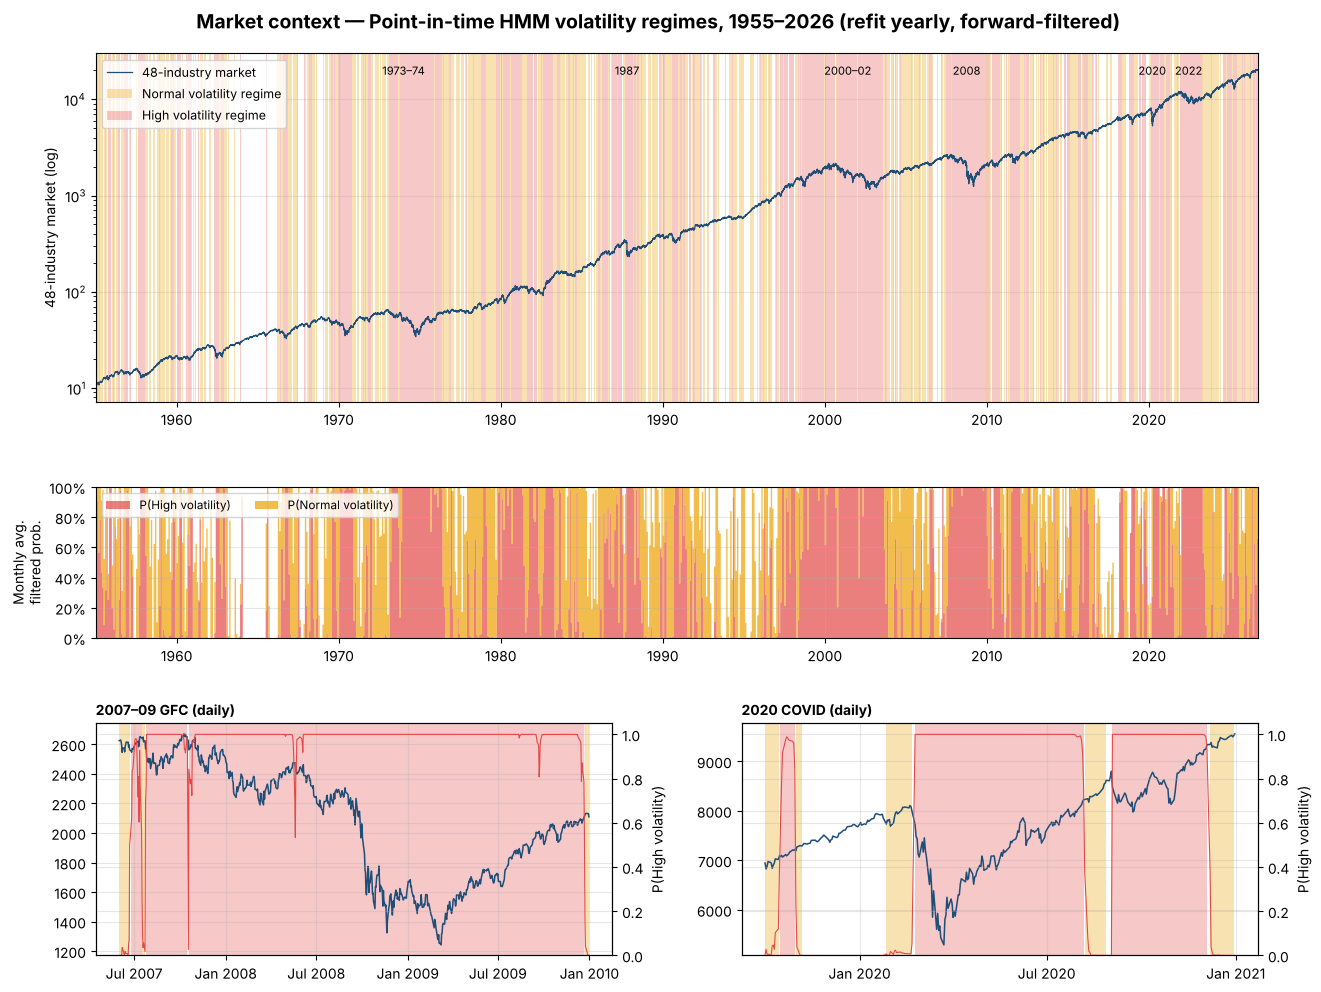

In [15]:
px = mkt_daily.reindex(filt.index)
CRISIS_LABELS = {"1973–74": "1974-01-01", "1987": "1987-10-19", "2000–02": "2001-06-01",
                 "2008": "2008-10-01", "2020": "2020-03-16", "2022": "2022-06-15"}

fig = plt.figure(figsize=(15, 11))
gs = fig.add_gridspec(3, 2, height_ratios=[3, 1.3, 2], hspace=0.35, wspace=0.25, top=0.93)
fig.suptitle(f"Market context — Point-in-time HMM volatility regimes, {filt.index[0]:%Y}–{filt.index[-1]:%Y} "
             "(refit yearly, forward-filtered)", fontsize=14, fontweight="bold", y=0.97)
ax1 = fig.add_subplot(gs[0, :])
ax1.plot(px.index, px, color="#1f4e79", lw=0.9, label=MKT_NAME)
for r in REGIMES[1:]:
    ax1.fill_between(regime.index, 0, 1, where=regime.eq(r).values, step="post", color=REGIME_COLORS[r],
                     alpha=0.3, lw=0, transform=ax1.get_xaxis_transform(), label=f"{r} regime")
for lab, d in CRISIS_LABELS.items():
    ax1.text(pd.Timestamp(d), 0.97, lab, transform=ax1.get_xaxis_transform(), ha="center", va="top", fontsize=8)
ax1.set(yscale="log", ylabel=f"{MKT_NAME} (log)", xlim=(filt.index[0], filt.index[-1]))
ax1.legend(loc="upper left", fontsize=9)

ax2 = fig.add_subplot(gs[1, :], sharex=ax1)
ax2.stackplot(regime_m.index, regime_m[REGIMES[2]], regime_m[REGIMES[1]], step="post", alpha=0.7,
              labels=[f"P({REGIMES[2]})", f"P({REGIMES[1]})"], colors=[REGIME_COLORS[REGIMES[2]], REGIME_COLORS[REGIMES[1]]])
ax2.set(ylim=(0, 1), ylabel="Monthly avg.\nfiltered prob.")
ax2.yaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
ax2.legend(loc="upper left", ncol=2, fontsize=8.5)

for k, (title, a, b) in enumerate([("2007–09 GFC (daily)", "2007-06-01", "2009-12-31"),
                                   ("2020 COVID (daily)", "2019-10-01", "2020-12-31")]):
    ax = fig.add_subplot(gs[2, k])
    for r in REGIMES[1:]:
        ax.fill_between(regime.loc[a:b].index, 0, 1, where=regime.loc[a:b].eq(r).values, step="post",
                        color=REGIME_COLORS[r], alpha=0.3, lw=0, transform=ax.get_xaxis_transform())
    ax.plot(px.loc[a:b], color="#1f4e79", lw=1.1)
    axr = ax.twinx()
    axr.plot(filt.loc[a:b, "High volatility"], color=REGIME_COLORS["High volatility"], lw=0.8)
    axr.set(ylim=(0, 1.05), ylabel="P(High volatility)")
    ax.set_title(title, loc="left", fontsize=10, fontweight="bold")
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
for ax in fig.axes:
    ax.grid(True, alpha=0.3)
save(fig, "layer2_hmm_regimes")

## 3.4 Validation against known crises and NBER recessions
* **Purpose:** Give the regimes a meaning that a person can check, instead of leaving them as state numbers.
* **Method:** For each crisis, the peak and trough of the index are found inside a search window (ex-post, validation only) and the share of High-volatility days is counted. The last row gives the same share over all days: the High-volatility state covers a large part of the sample, so a high share inside a crisis must be read against that reference. The second table compares regime shares in NBER recessions and expansions. The state is a broad volatility regime, not a crisis or recession detector.

In [16]:
CRISIS_SEARCH = {"1973-74 oil shock": ("1972-06-01", "1974-12-31"), "1987 crash": ("1987-06-01", "1987-12-31"),
                 "2000-02 dot-com": ("2000-01-01", "2002-12-31"), "2007-09 GFC": ("2007-06-01", "2009-06-30"),
                 "2020 COVID": ("2020-01-01", "2020-06-30"), "2022 rates": ("2021-11-01", "2022-12-31")}
rows = []
for name, (a, b) in CRISIS_SEARCH.items():
    w = mkt_daily.loc[a:b]
    peak, trough = w.idxmax(), w.loc[w.idxmax():].idxmin()
    r = regime.loc[peak:trough]
    first = r[r == "High volatility"].index.min()
    rows.append({"Crisis (peak to trough)": name, "Days": len(r), "% High volatility": (r == "High volatility").mean() * 100,
                 "Days from peak to first High-volatility day": (first - peak).days if pd.notna(first) else np.nan})
rows.append({"Crisis (peak to trough)": "All days (reference)", "Days": len(regime),
             "% High volatility": (regime == "High volatility").mean() * 100})
crisis_check = pd.DataFrame(rows).set_index("Crisis (peak to trough)")

rec_d = pd.Series(usrec.set_axis(usrec.index.to_period("M")).reindex(regime.index.to_period("M")).values, index=regime.index)
ok = rec_d.notna()
rec_tab = pd.crosstab(rec_d[ok].map({1.0: "NBER recession", 0.0: "Expansion"}).rename("Period"),
                      regime[ok].rename("Regime"), normalize="index").reindex(columns=REGIMES) * 100
display(crisis_check.round(1), rec_tab.round(1))

,Days,% High volatility,Days from peak to first High-volatility day
Crisis (peak to trough),,,
1973-74 oil shock,437,87.4,34.0
1987 crash,72,94.4,6.0
2000-02 dot-com,526,93.3,27.0
2007-09 GFC,356,99.4,0.0
2020 COVID,24,87.5,5.0
2022 rates,198,100.0,0.0
All days (reference),18057,44.4,NaN


Regime,Low volatility,Normal volatility,High volatility
Period,,,
Expansion,18.9,41.9,39.2
NBER recession,3.5,13.6,82.9


## 3.5 Look-ahead test for Layer 2
* **Purpose:** Prove that the regime at day *t* does not use data after *t*.
* **Method:** Truncation test in two parts: (1) filtering data cut at a past date must reproduce the same probabilities; (2) refitting at the last fit date before the cut must reproduce the same parameters.

In [17]:
rows = []
for cut in ["1987-10-30", "2008-12-31", "2020-03-31"]:
    part, reg_p, _ = hmm_realtime(hmm_df.loc[:cut], cache=hmm_rt_models)
    same_filter = np.allclose(filt.loc[part.index].values, part.values, atol=1e-10) and regime.loc[reg_p.index].equals(reg_p)
    fd = max(d for d in hmm_rt_models if d <= pd.Timestamp(cut))
    prev = hmm_rt_models.get(fd - pd.DateOffset(years=1))
    train = hmm_df.loc[:fd]
    sc = StandardScaler().fit(train)
    m = fit_hmm(sc.transform(train), init=None if prev is None else prev[0])
    m0, sc0, _ = hmm_rt_models[fd]
    same_fit = np.allclose(sc.mean_, sc0.mean_) and np.allclose(m.means_, m0.means_)
    assert same_filter and same_fit, f"look-ahead in the HMM at {cut}"
    rows.append({"Cut date": cut, "Days compared": len(part), "Filter identical": same_filter,
                 "Refit date": f"{fd:%Y-%m-%d}", "Refit identical": same_fit})
pd.DataFrame(rows)

,Cut date,Days compared,Filter identical,Refit date,Refit identical
0,1987-10-30,8256,True,1986-12-31,True
1,2008-12-31,13594,True,2008-12-31,True
2,2020-03-31,16424,True,2019-12-31,True


# Part 4 — Features and targets

## 4.1 Industry features
* **Purpose:** Describe each industry at month *t* with information available at *t* only.
* **Method:** Every continuous feature is turned into a **cross-sectional percentile rank** among eligible industries in the same month. Ranks keep the same scale in 1935 and in 2020, so a model trained on old data is not asked to extrapolate. Three features target bubbles specifically: `EW_Tilt` (equal- minus value-weighted 24-month return, a proxy for a tilt towards small and young firms), `Net24_x_VolChg` (volatility that rises during a run-up) and `PSY_Margin` (strength of the Layer 1 signal).

| Group | Features |
|---|---|
| Price run-up | `RunUp` flag, `Net24` (24M return net of market), `Accel` (last 12M versus the 12M before) |
| Volatility | `Vol_pre` (before the run-up), `Vol6` (last 6 months), `Vol_Chg` (change in volatility) |
| Issuance / valuation | `Firms_Chg24` (growth in firm count), `BM` (book-to-market) |
| Bubble signals | `EW_Tilt`, `Net24_x_VolChg`, `PSY_Margin` |
| Own history (not ranked) | `Vol_Own`, `R24_Own` (percentile within the industry's own last 10 years), `DD60` (distance from the 5-year high) |

Ranks remove everything that all industries share, including the level of market-wide risk. The own-history group puts that level back; it is tested in the ablation (6.7) and is not part of the main model.

In [18]:
def lag_return(r, k):
    # cumulative k-month return ending at t; missing if any month in the window is missing
    return np.expm1(np.log1p(r).rolling(k, min_periods=k).sum())

eligible = nfirms >= MIN_FIRMS
xrank = lambda df: df.where(eligible).rank(axis=1, pct=True)        # rank within the month, eligible industries only

price = np.exp(np.log1p(ret).cumsum())                              # total-return index of each industry
R24, R60 = lag_return(ret, 24), lag_return(ret, 60)
Net24 = R24.sub(lag_return(mkt, 24), axis=0)

vol_d = dret.groupby(dret.index.to_period("M")).std() * np.sqrt(TRADING_DAYS)   # daily data -> x sqrt(252)
vol_d = vol_d.set_axis(vol_d.index.to_timestamp("M")).reindex(ret.index)
vol6  = vol_d.rolling(6, min_periods=4).mean()

nf_pos = nfirms.where(nfirms > 0)
bm = be_me.where(be_me > 0)
bm.index = pd.to_datetime([f"{int(y)+1}-07-01" for y in bm.index]) + pd.offsets.MonthEnd(0)
bm = bm.reindex(bm.index.union(ret.index)).ffill(limit=11).reindex(ret.index)    # annual value kept <= 11 months

RAW = {"Net24":          Net24,
       "Accel":          lag_return(ret, 12) - lag_return(ret, 12).shift(12),
       "Vol_pre":        ret.shift(24).rolling(12, min_periods=10).std() * np.sqrt(12),   # monthly data -> x sqrt(12)
       "Vol6":           vol6,
       "Vol_Chg":        np.log(vol6 / vol_d.shift(12).rolling(12, min_periods=8).mean()),
       "Firms_Chg24":    np.log(nf_pos / nf_pos.shift(24)),
       "BM":             bm,
       "EW_Tilt":        lag_return(ret_ew, 24) - R24,
       "PSY_Margin":     ind_margin}
RAW["Net24_x_VolChg"] = RAW["Net24"] * RAW["Vol_Chg"]

RUNUP = ((R24 >= RUNUP_2Y) & (Net24 >= RUNUP_2Y) & (R60 >= RUNUP_5Y)).astype(float).where(R60.notna() & Net24.notna())
own_pct = lambda df: df.rolling(120, min_periods=60).rank(pct=True)     # percentile within the industry's own last 10 years
W = {"RunUp": RUNUP, **{f"{k}_R": xrank(v) for k, v in RAW.items()}, **RAW,
     "Vol_Own": own_pct(vol6), "R24_Own": own_pct(R24), "DD60": price / price.rolling(60, min_periods=60).max() - 1,
     "R24": R24, "DD12": price / price.rolling(12, min_periods=12).max() - 1}

FEATS_VOL    = ["Vol_pre_R", "Vol6_R"]                                               # volatility-only baseline
FEATS_MAIN   = ["RunUp", "Net24_R", "Accel_R", "Vol_pre_R", "Vol6_R", "Vol_Chg_R", "Firms_Chg24_R", "BM_R"]
FEATS_BUBBLE = ["EW_Tilt_R", "Net24_x_VolChg_R", "PSY_Margin_R"]
FEATS_OWN    = ["Vol_Own", "R24_Own", "DD60"]
FEATS_RAW    = ["RunUp", "Net24", "Accel", "Vol_pre", "Vol6", "Vol_Chg", "Firms_Chg24", "BM"]       # no ranks at all, robustness only
assert not any(f.endswith("_R") for f in FEATS_RAW)
FEAT_GROUP   = {"Price run-up": ["RunUp", "Net24_R", "Accel_R"], "Volatility": ["Vol_pre_R", "Vol6_R", "Vol_Chg_R"],
                "Issuance / valuation": ["Firms_Chg24_R", "BM_R"]}

## 4.2 Targets: two definitions of a severe drawdown
* **Purpose:** Define what each function is measured against. The two core functions use different targets on purpose, so an industry can count as a severe drawdown for one and not for the other.
* **Method:** Both are drawdowns of a monthly **total-return** index (dividends reinvested, the equivalent of adjusted prices), measured from the **running peak reached from month *t* onwards**, within the next *H* months. The target is missing when the future window is incomplete, so unfinished windows are never counted as "no drawdown".

| Function | Target | Why |
|---|---|---|
| Risk Ranking (Part 6) | Relative drawdown ≥ 30%: the industry index **divided by the market** falls 30% from its running peak within 24 months (also 6 and 12) | Ranks industries against each other; a fall that only mirrors the whole market does not count |
| Run-up Watch (Part 7) | Absolute drawdown ≥ 40%: the industry index itself falls 40% from its running peak within 24 months | The definition of Greenwood, Shleifer & You (2019), so the run-up results can be compared with the paper |

"Severe drawdown" is used instead of "crash" because the event is industry-specific and is not a market-wide crisis.

In [19]:
def crash_label(px, H, dd):
    run_max, max_dd = px.copy(), pd.DataFrame(0.0, index=px.index, columns=px.columns)
    for k in range(1, H + 1):
        run_max = np.fmax(run_max, px.shift(-(k - 1)))
        max_dd  = np.fmax(max_dd, 1 - px.shift(-k) / run_max)
    n_obs = ret.notna().astype(int).rolling(H, min_periods=H).sum().shift(-H)
    complete = px.shift(-H).notna() & px.notna() & n_obs.eq(H)
    return (max_dd >= dd).astype(float).where(complete)

rel_px    = price.div(np.exp(np.log1p(mkt).cumsum()), axis=0)       # industry price relative to the market
CRASH     = {H: crash_label(rel_px, H, REL_DD) for H in H_LIST}     # headline: relative to the market
CRASH_ABS = crash_label(price, MAIN_H, ABS_DD)                      # secondary: absolute

both = CRASH[MAIN_H].stack().to_frame("rel").join(CRASH_ABS.stack().rename("abs")).dropna()
label_table = pd.DataFrame(
    [{"Label": f"Crash_{H} (>= {REL_DD:.0%} vs market in {H}M)", "Base rate": CRASH[H].stack().mean(),
      "Last labelled month": f"{CRASH[H].dropna(how='all').index.max():%Y-%m}"} for H in H_LIST] +
    [{"Label": f"CrashAbs_{MAIN_H} (>= {ABS_DD:.0%} in {MAIN_H}M)", "Base rate": CRASH_ABS.stack().mean(),
      "Last labelled month": f"{CRASH_ABS.dropna(how='all').index.max():%Y-%m}"}]).set_index("Label")
print(f"Share of {MAIN_H}M absolute severe drawdowns that are also relative ones: {both.loc[both['abs'] == 1, 'rel'].mean():.1%}")
label_table.round(3)

Share of 24M absolute severe drawdowns that are also relative ones: 65.0%


,Base rate,Last labelled month
Label,,
Crash_6 (>= 30% vs market in 6M),0.020,2026-03
Crash_12 (>= 30% vs market in 12M),0.065,2025-09
Crash_24 (>= 30% vs market in 24M),0.175,2024-09
CrashAbs_24 (>= 40% in 24M),0.139,2024-09


## 4.3 Severe-drawdown events and the business cycle
* **Purpose:** Measure how many absolute severe drawdowns simply come with a recession.
* **Method:** Descriptive, with hindsight. An absolute crash event starts in the first month an industry is at least 40% below its 24-month high; a new event needs more than 24 months since the previous one. Events are compared with NBER recession months. A high share inside recessions means the absolute definition mostly captures market-wide falls, which is why the Risk Ranking uses the relative target.

In [20]:
dd24 = price / price.rolling(24, min_periods=1).max() - 1
event_rows = []
for ind in INDS:
    last = None
    for d in dd24.index[dd24[ind] <= -ABS_DD]:
        if last is None or (d.to_period("M") - last.to_period("M")).n > 24:
            event_rows.append({"Industry": ind, "Onset": d})
            last = d
EVENTS = pd.DataFrame(event_rows)

rec_m = usrec.reindex(ret.index).ffill(limit=FRED_FFILL)
near  = rec_m.rolling(25, center=True, min_periods=1).max()         # recession within +/- 12 months (ex-post description)
ev = EVENTS[EVENTS["Onset"] >= rec_m.first_valid_index()]
top_years = ev.groupby(ev["Onset"].dt.year).size().nlargest(5)
pd.Series({"Crash events": len(ev),
           "Onset during a recession (%)": round(100 * ev["Onset"].map(rec_m).eq(1).mean(), 1),
           "Share of all months in recession (%)": round(100 * rec_m.mean(), 1),
           "Onset within 12 months of a recession (%)": round(100 * ev["Onset"].map(near).eq(1).mean(), 1),
           "Years with the most onsets": ", ".join(f"{y} ({n})" for y, n in top_years.items())}, name="Value", dtype=object).to_frame()

,Value
Crash events,360
Onset during a recession (%),62.5
Share of all months in recession (%),16.7
Onset within 12 months of a recession (%),72.2
Years with the most onsets,"2008 (35), 1937 (26), 1974 (22), 1970 (20), 1930 (19)"


## 4.4 Panel: one row per industry-month
* **Purpose:** Put features, labels and weights in one table for the models.
* **Method:** Rows need at least 10 firms and a complete main feature set. The number of rows removed at each step is reported instead of being dropped silently. A row is `Masked` when the industry is already 20% below its 12-month high: such months are not early warnings, so they are excluded from training and from evaluation. HMM probabilities are attached for the ablation test.

In [21]:
idx  = pd.MultiIndex.from_product([ret.index, INDS], names=["Date", "Industry"])
wide = {**W, "NFirms": nfirms, "MCap": mcap, "PSY_Bubble": ind_psy,
        **{f"Crash_{H}": CRASH[H] for H in H_LIST}, f"CrashAbs_{MAIN_H}": CRASH_ABS}
full = pd.DataFrame({k: v.reindex(index=ret.index, columns=INDS).values.ravel() for k, v in wide.items()}, index=idx)
full = full[full["NFirms"].notna()]
enough = full[full["NFirms"] >= MIN_FIRMS]
panel  = enough.dropna(subset=FEATS_MAIN).copy()
panel["Masked"] = panel["DD12"] <= MASK_DD12
panel["Year"]   = panel.index.get_level_values("Date").year
for r in REGIMES[1:]:
    panel[f"HMM_{r}"] = regime_m[r].reindex(panel.index.get_level_values("Date")).values
panel["Net24_x_HighVol"] = panel["Net24_R"] * panel["HMM_High volatility"]

assert not panel.index.duplicated().any()
assert np.isfinite(panel[FEATS_MAIN]).all().all()
assert panel[FEATS_MAIN].drop(columns="RunUp").stack().between(0, 1).all(), "rank features must lie in [0, 1]"
pd.Series({"Industry-months with data": len(full),
           f"Removed: fewer than {MIN_FIRMS} firms": len(full) - len(enough),
           "Removed: incomplete feature history (warm-up)": len(enough) - len(panel),
           "Panel rows": len(panel),
           "First year": panel["Year"].min(), "Last year": panel["Year"].max(),
           "Masked rows (already falling) %": round(100 * panel["Masked"].mean(), 1),
           "Strict run-up rows (RunUp = 1) %": round(100 * panel["RunUp"].mean(), 2),
           "Rows with all bubble-signal and own-history features %": round(100 * panel[FEATS_BUBBLE + FEATS_OWN].notna().all(axis=1).mean(), 1)},
          name="Value", dtype=object).to_frame()

,Value
Industry-months with data,57744
Removed: fewer than 10 firms,15047
Removed: incomplete feature history (warm-up),1262
Panel rows,41435
First year,1931
Last year,2026
Masked rows (already falling) %,12.3
Strict run-up rows (RunUp = 1) %,0.8
Rows with all bubble-signal and own-history features %,98.7


## 4.5 Feature correlation
* **Purpose:** See which features carry the same information.
* **Method:** Spearman rank correlation over the whole panel. Strongly correlated features share importance in a tree model and can flip sign in a Logit, so effects are read by feature group (Part 7).

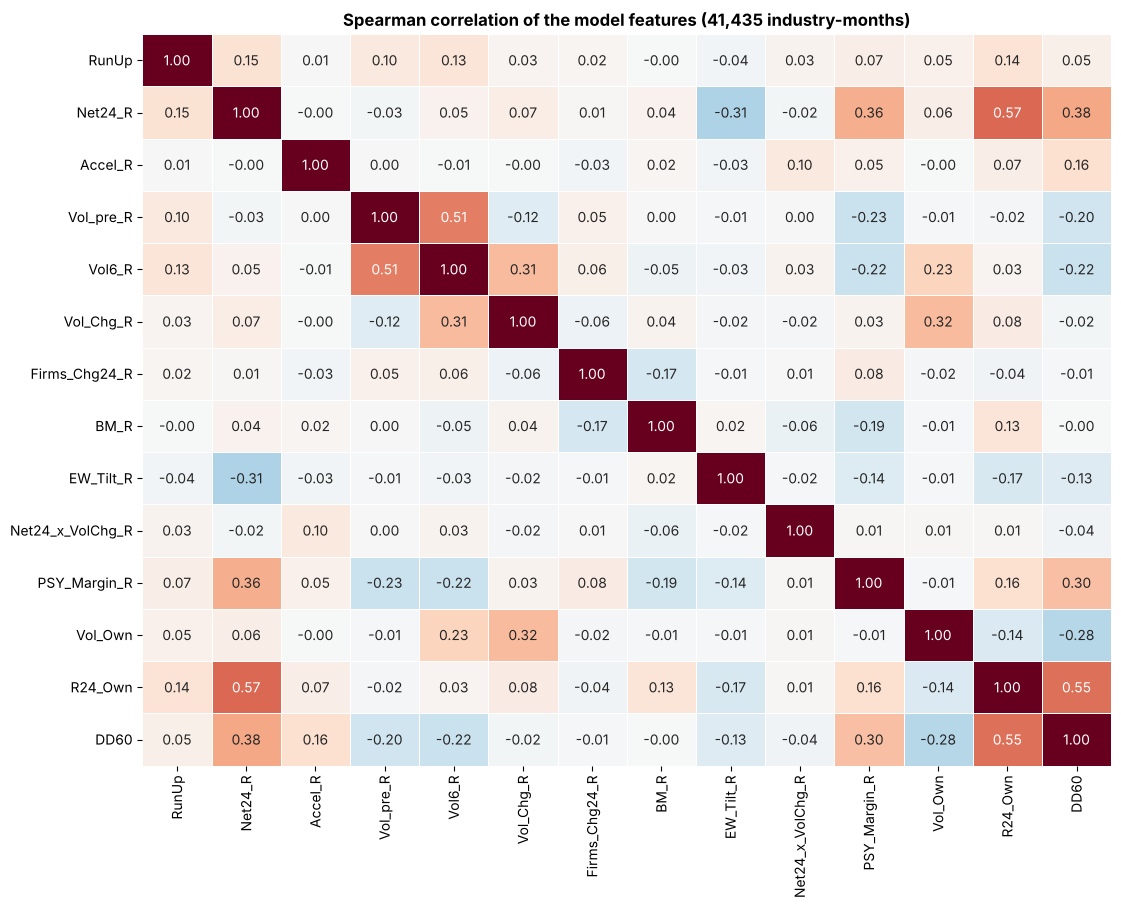

In [22]:
fig, ax = plt.subplots(figsize=(12.5, 9.5))
sns.heatmap(panel[FEATS_MAIN + FEATS_BUBBLE + FEATS_OWN].corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r",
            vmin=-1, vmax=1, center=0, linewidths=0.5, cbar=False, ax=ax)
ax.set_title(f"Spearman correlation of the model features ({len(panel):,} industry-months)", fontsize=12, fontweight="bold")
save(fig, "feature_correlation")

# Part 5 — Walk-forward models

## 5.1 Models
* **Purpose:** Define the benchmark ladder: base rate → volatility-only Logit → Logit → Random Forest. The volatility-only model is the traditional risk measure that the Random Forest has to beat.
* **Method:** Each model is a `Pipeline`, so the winsoriser and the scaler are fitted on the training rows only. `Logit-Vol` uses two volatility ranks and nothing else. If it ranks industries as well as the full models, the system is a volatility ranker and not a bubble detector.

In [23]:
class Winsorizer(BaseEstimator, TransformerMixin):
    """Clip continuous features to training-set quantiles; 0/1 flags are left unchanged."""
    def __init__(self, lower=WINSOR[0], upper=WINSOR[1]):
        self.lower, self.upper = lower, upper
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.lo_, self.hi_ = np.quantile(X, [self.lower, self.upper], axis=0)
        flag = np.array([np.unique(c).size <= 2 for c in X.T])
        self.lo_[flag], self.hi_[flag] = -np.inf, np.inf
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lo_, self.hi_)

def make_model(kind):
    if kind == "rf":
        clf = RandomForestClassifier(n_estimators=200, max_depth=4, min_samples_leaf=300, max_samples=0.5,
                                     n_jobs=-1, random_state=SEED)
        return Pipeline([("clip", Winsorizer()), ("clf", clf)])
    return Pipeline([("clip", Winsorizer()), ("scale", StandardScaler()), ("clf", LogisticRegression(C=1.0, max_iter=3000))])

MODEL_SPECS = {VOL_MODEL:   ("logit", FEATS_VOL),
               BENCH_MODEL: ("logit", FEATS_MAIN),
               MAIN_MODEL:  ("rf",    FEATS_MAIN)}
MODELS = list(MODEL_SPECS)

## 5.2 Walk-forward engine
* **Purpose:** Produce out-of-sample probabilities with one function that every later test reuses.
* **Method:** For each test year *Y* the model is fitted on rows dated up to 31 December of *Y−1*.
    * **Embargo:** a training row is used only if its label was already known at the fit date (*t + H* ≤ fit date).
    * **Time decay:** training rows are weighted by 0.5^(age / half-life), so the oldest data do not dominate. The base rate is the weighted crash rate of the same training rows. The half-life is chosen in 5.3.
    * **Masked rows** are excluded from training.

In [24]:
CARRY = ["Masked", "MCap", "RunUp", "PSY_Bubble", "R24", "Net24_R"]     # columns copied to the prediction table

def walk_forward(label, specs, H, rows=None, half_life=None, keep_years=(), years=None):
    """Returns (pred, fitted, insample): out-of-sample predictions, models of `keep_years`, in-sample AUC per fit."""
    data = panel if rows is None else rows
    half_life = HALF_LIFE if half_life is None else half_life
    lab = data[data[label].notna() & ~data["Masked"]]
    lab_dates = lab.index.get_level_values("Date")
    preds, fitted, insample = [], {}, []
    for year in (years or range(FIRST_TEST_YEAR, data["Year"].max() + 1)):
        fit_date = pd.Timestamp(f"{year - 1}-12-31")
        train = lab[lab_dates <= fit_date - pd.DateOffset(months=H)]            # embargo
        test = data[data["Year"] == year]
        if test.empty or len(train) < MIN_TRAIN or train[label].nunique() < 2:
            continue
        age = np.asarray((fit_date - train.index.get_level_values("Date")).days) / 365.25
        w = 0.5 ** (age / half_life)                                            # half_life = inf gives equal weights
        y_tr = train[label].astype(int).values
        out = test[[label] + CARRY].rename(columns={label: "y"})
        out["Base rate"] = np.average(y_tr, weights=w)
        for name, (kind, feats) in specs.items():
            ok_tr, ok_te = train[feats].notna().all(axis=1).values, test[feats].notna().all(axis=1).values
            out[name] = np.nan
            if ok_tr.sum() < MIN_TRAIN or len(set(y_tr[ok_tr])) < 2 or not ok_te.any():
                continue
            model = make_model(kind).fit(train.loc[ok_tr, feats], y_tr[ok_tr], clf__sample_weight=w[ok_tr])
            out.loc[ok_te, name] = model.predict_proba(test.loc[ok_te, feats])[:, 1]
            p_in, y_in, yr_in = model.predict_proba(train.loc[ok_tr, feats])[:, 1], y_tr[ok_tr], train["Year"].values[ok_tr]
            insample.append({"Year": year, "Model": name,                        # AUC inside each training year, averaged
                             "AUC in-sample": np.mean([roc_auc_score(y_in[yr_in == k], p_in[yr_in == k])
                                                       for k in np.unique(yr_in) if 0 < y_in[yr_in == k].mean() < 1])})
            if year in keep_years:
                fitted[(year, name)] = model
        preds.append(out)
    return pd.concat(preds).sort_index(), fitted, pd.DataFrame(insample)

## 5.3 Choose the half-life before the test period
* **Purpose:** Set the time-decay half-life without looking at the test years.
* **Method:** Nested walk-forward. The main and benchmark models are run over 1945–1959 only, once for each candidate half-life. The half-life with the highest pooled AUC of the main model on those validation years is locked and used for every test year from 1960. The rule was fixed before the run.

In [25]:
valid_rows = []
for hl in HALF_LIFE_GRID:
    v, _, _ = walk_forward(f"Crash_{MAIN_H}", {m: MODEL_SPECS[m] for m in [BENCH_MODEL, MAIN_MODEL]}, MAIN_H, half_life=hl, years=VALID_YEARS)
    v = v[~v["Masked"] & v["y"].notna()]
    valid_rows.append({"Half-life (years)": hl, "Rows": len(v), "Crash rate": v["y"].mean(),
                       **{f"AUC {m}": roc_auc_score(v["y"], v[m]) for m in [MAIN_MODEL, BENCH_MODEL]},
                       **{f"Brier {m}": ((v[m] - v["y"]) ** 2).mean() for m in [MAIN_MODEL, BENCH_MODEL]}})
half_life_table = pd.DataFrame(valid_rows).set_index("Half-life (years)")
HALF_LIFE = half_life_table[f"AUC {MAIN_MODEL}"].idxmax()
half_life_table["Chosen"] = half_life_table.index == HALF_LIFE
half_life_table.round(4)

,Rows,Crash rate,AUC RandomForest,AUC Logit,Brier RandomForest,Brier Logit,Chosen
Half-life (years),,,,,,,
10.0,4382,0.0504,0.5652,0.5564,0.0489,0.0504,False
20.0,4382,0.0504,0.6027,0.5694,0.0493,0.0512,False
40.0,4382,0.0504,0.6145,0.5750,0.0497,0.0517,False
inf,4382,0.0504,0.6258,0.5796,0.0502,0.0524,True


## 5.4 Run the models
* **Purpose:** Fit every model at every horizon, plus the two side tests.
* **Method:**
    * `PRED[H]` — Risk Ranking target (relative) for 6, 12 and 24 months.
    * `PRED_ABS` — absolute target at 24 months, for comparison.
    * `ABL` — ablation at 24 months on identical rows: does adding the bubble signals (Layer 1), the HMM regime (Layer 2) or the own-history features help?

In [26]:
PRED, INSAMPLE = {}, {}
for H in H_LIST:
    PRED[H], fitted, INSAMPLE[H] = walk_forward(f"Crash_{H}", MODEL_SPECS, H, keep_years=[*EXPLAIN_YEARS.values(), panel["Year"].max()])
    if H == MAIN_H:
        FITTED = fitted
PRED_ABS, _, _ = walk_forward(f"CrashAbs_{MAIN_H}", MODEL_SPECS, MAIN_H)

HMM_FEATS = [f"HMM_{r}" for r in REGIMES[1:]]
ABL_SETS = {"Main": FEATS_MAIN, "Main + bubble signals": FEATS_MAIN + FEATS_BUBBLE,
            "Main + HMM regime": FEATS_MAIN + HMM_FEATS, "Main + own history": FEATS_MAIN + FEATS_OWN,
            "Main + all": FEATS_MAIN + FEATS_BUBBLE + HMM_FEATS + FEATS_OWN}
ABL_SPECS = {f"{fam} | {name}": (kind, feats + (["Net24_x_HighVol"] if kind == "logit" and HMM_FEATS[0] in feats else []))
             for kind, fam in [("logit", "Logit"), ("rf", "RF")] for name, feats in ABL_SETS.items()}   # a Logit needs the interaction spelled out
abl_rows = panel.dropna(subset=FEATS_BUBBLE + HMM_FEATS + FEATS_OWN)             # same rows for every variant
ABL, _, _ = walk_forward(f"Crash_{MAIN_H}", ABL_SPECS, MAIN_H, rows=abl_rows)

for name, p in {**{f"PRED[{H}]": PRED[H] for H in H_LIST}, "PRED_ABS": PRED_ABS, "ABL": ABL}.items():
    assert p[[c for c in p.columns if c in MODELS or " | " in c]].stack().between(0, 1).all(), f"{name}: P outside [0, 1]"
coverage = pd.DataFrame({name: {"First month": f"{p.index.get_level_values('Date').min():%Y-%m}",
                                "Last month": f"{p.index.get_level_values('Date').max():%Y-%m}",
                                "Rows": len(p), "Labelled rows": int(p["y"].notna().sum())}
                         for name, p in {**{f"Crash_{H}": PRED[H] for H in H_LIST}, f"CrashAbs_{MAIN_H}": PRED_ABS,
                                         "Ablation": ABL}.items()}).T
coverage

,First month,Last month,Rows,Labelled rows
Crash_6,1960-01,2026-09,33360,33125
Crash_12,1960-01,2026-09,33360,32885
Crash_24,1960-01,2026-09,33360,32384
CrashAbs_24,1960-01,2026-09,33360,32384
Ablation,1961-01,2026-09,32950,31974


# Part 6 — Core 1: Industry Risk Ranking

## 6.1 Metrics and bootstrap
* **Purpose:** Define how ranking skill is measured and how uncertainty is estimated.
* **Method:**
    * **XS-AUC** — ranking skill across industries inside one month, averaged over months. An XS-AUC of 0.70 means that, for a random pair of industries in the same month where only one goes on to a severe drawdown, the model ranks that one higher 70% of the time. It is **not** the share of drawdowns predicted correctly.
    * **Time-AUC** — timing skill: each row gets its month's average prediction. The reference is 0.5.
    * **AUC** — pooled; **BSS** — accuracy of the probabilities against the training base rate (0 = no better).
    * **Intervals** — moving-block bootstrap over whole months (24-month blocks), because industries fall together and 24-month windows overlap. Rows are never resampled independently.
    * **Early-warning rows** — months in which the industry is not already 20% below its 12-month high.

In [27]:
def block_positions(n, seed=SEED):
    rng = np.random.default_rng(seed)                               # same seed -> comparisons between models are paired
    for _ in range(N_BOOT):
        starts = rng.integers(0, n - BLOCK + 1, size=int(np.ceil(n / BLOCK)))
        yield np.concatenate([np.arange(s, s + BLOCK) for s in starts])[:n]

def early_warning(pred):
    return pred[~pred["Masked"] & pred["y"].notna()]

def xs_auc(df, col):
    return pd.Series({d: roc_auc_score(g["y"], g[col]) for d, g in df.groupby(level="Date")
                      if g["y"].nunique() == 2 and g[col].nunique() > 1}, dtype=float)

def bss(y, p, base):
    return 1 - np.mean((p - y) ** 2) / np.mean((base - y) ** 2)

def metric_draws(df, col):
    """Point estimate (row 0) and bootstrap draws of [XS-AUC, Time-AUC, AUC, PR lift, BSS] for one model column."""
    y, p, base = df["y"].values.astype(int), df[col].values, df["Base rate"].values
    p_time = df.groupby(level="Date")[col].transform("mean").values
    codes, months = pd.factorize(df.index.get_level_values("Date"))
    rows_of = [np.flatnonzero(codes == k) for k in range(len(months))]
    xs = xs_auc(df, col).reindex(months).values
    def calc(pos):
        ix = np.concatenate([rows_of[k] for k in pos])
        if y[ix].min() == y[ix].max():
            return [np.nan] * 5
        x = xs[pos]
        return [np.nanmean(x) if np.isfinite(x).any() else np.nan, roc_auc_score(y[ix], p_time[ix]),
                roc_auc_score(y[ix], p[ix]), average_precision_score(y[ix], p[ix]) / y[ix].mean(), bss(y[ix], p[ix], base[ix])]
    return np.array([calc(np.arange(len(months)))] + [calc(pos) for pos in block_positions(len(months))])

METRICS = ["XS-AUC", "Time-AUC", "AUC", "PR lift", "BSS"]

def evaluate(df, models):
    df = df.dropna(subset=["y", "Base rate"] + models).sort_index()
    out = {}
    for m in models:
        d = metric_draws(df, m)
        lo, hi = np.nanpercentile(d[1:], [2.5, 97.5], axis=0)
        out[m] = {"N": len(df), "Crash rate": df["y"].mean(), **dict(zip(METRICS, d[0])),
                  **{f"{k} lo": v for k, v in zip(METRICS, lo)}, **{f"{k} hi": v for k, v in zip(METRICS, hi)}}
    return pd.DataFrame(out).T.astype({"N": int})

def paired_diff(df, a, b):
    """Bootstrap difference a - b on identical rows and months; p = two-sided bootstrap p-value."""
    df = df.dropna(subset=["y", "Base rate", a, b]).sort_index()
    d = metric_draws(df, a) - metric_draws(df, b)
    row = {}
    for k, name in enumerate(METRICS):
        if name == "PR lift":
            continue
        draws = d[1:, k][np.isfinite(d[1:, k])]
        row.update({f"Δ{name}": d[0, k], f"Δ{name} lo": np.percentile(draws, 2.5), f"Δ{name} hi": np.percentile(draws, 97.5),
                    f"p {name}": max(2 * min((draws <= 0).mean(), (draws >= 0).mean()), 1 / N_BOOT)})
    return row

def top_k_alert(pred, model, k=ALERT_K):
    p = pred[model].where(~pred["Masked"])
    return p.groupby(level="Date").rank(ascending=False, method="first") <= k

EW = {H: early_warning(PRED[H]) for H in H_LIST}
EW_ABS = early_warning(PRED_ABS)

def month_boot(df, stat):
    """Point estimate and month-block bootstrap interval of stat(row_positions); df must be sorted by date."""
    codes, months = pd.factorize(df.index.get_level_values("Date"))
    rows_of = [np.flatnonzero(codes == k) for k in range(len(months))]
    point = np.asarray(stat(np.arange(len(df))), dtype=float)
    draws = np.array([stat(np.concatenate([rows_of[k] for k in pos])) for pos in block_positions(len(months))], dtype=float)
    return point, np.nanpercentile(draws, 2.5, axis=0), np.nanpercentile(draws, 97.5, axis=0), draws

def risk_level(pred, model=MAIN_MODEL):
    """Quartile of the monthly ranking among industries that are not already falling."""
    rank = pred[model].where(~pred["Masked"]).groupby(level="Date").rank(pct=True)
    return pd.cut(rank, [0, 0.25, 0.5, 0.75, 1.0], labels=LEVELS), rank

## 6.2 Ranking skill by horizon
* **Purpose:** Show how well each model ranks industries, out of sample, against the base rate and the volatility-only benchmark.
* **Method:** The 24-month horizon is the one used by the product; 6 and 12 months show that the result does not depend on one horizon. `Base rate` gives every industry the same score, so it has no ranking skill by construction.

In [28]:
results = {H: evaluate(EW[H], ["Base rate"] + MODELS) for H in H_LIST}
scorecard = pd.concat(results, names=["Horizon (months)", "Model"])
scorecard[["N", "Crash rate", "XS-AUC", "XS-AUC lo", "XS-AUC hi", "Time-AUC", "AUC", "BSS", "BSS lo", "BSS hi"]].rename(
    columns={"Crash rate": "Severe-drawdown rate"}).round(3)

N  Severe-drawdown rate  XS-AUC  XS-AUC lo  XS-AUC hi  Time-AUC    AUC    BSS  BSS lo  BSS hi
Horizon (months) Model                                                                                                          
6                Base rate     29213                 0.007     NaN        NaN        NaN     0.602  0.602  0.000   0.000   0.000
                 Logit-Vol     29213                 0.007   0.841      0.780      0.928     0.612  0.763  0.013   0.007   0.020
                 Logit         29213                 0.007   0.813      0.754      0.892     0.600  0.750  0.017   0.008   0.027
                 RandomForest  29213                 0.007   0.831      0.765      0.923     0.619  0.748  0.011   0.006   0.019
12               Base rate     28984                 0.035     NaN        NaN        NaN     0.561  0.561  0.000   0.000   0.000
                 Logit-Vol     28984                 0.035   0.783      0.738      0.848     0.562  0.666  0.022   0.011   0.036
                 Logit         28984                 0.035   0.750      0.701      0.823     0.591  0.656  0.029   0.011   0.053
                 RandomForest  28984                 0.035   0.782      0.733      0.842     0.564  0.669  0.023   0.012   0.038
24               Base rate     28503                 0.131     NaN        NaN        NaN     0.499  0.499  0.000   0.000   0.000
                 Logit-Vol     28503                 0.131   0.703      0.666      0.742     0.501  0.631  0.035   0.021   0.060
                 Logit         28503                 0.131   0.677      0.643      0.724     0.527  0.623  0.036   0.016   0.063
                 RandomForest  28503                 0.131   0.712      0.683      0.748     0.514  0.631  0.036   0.023   0.058

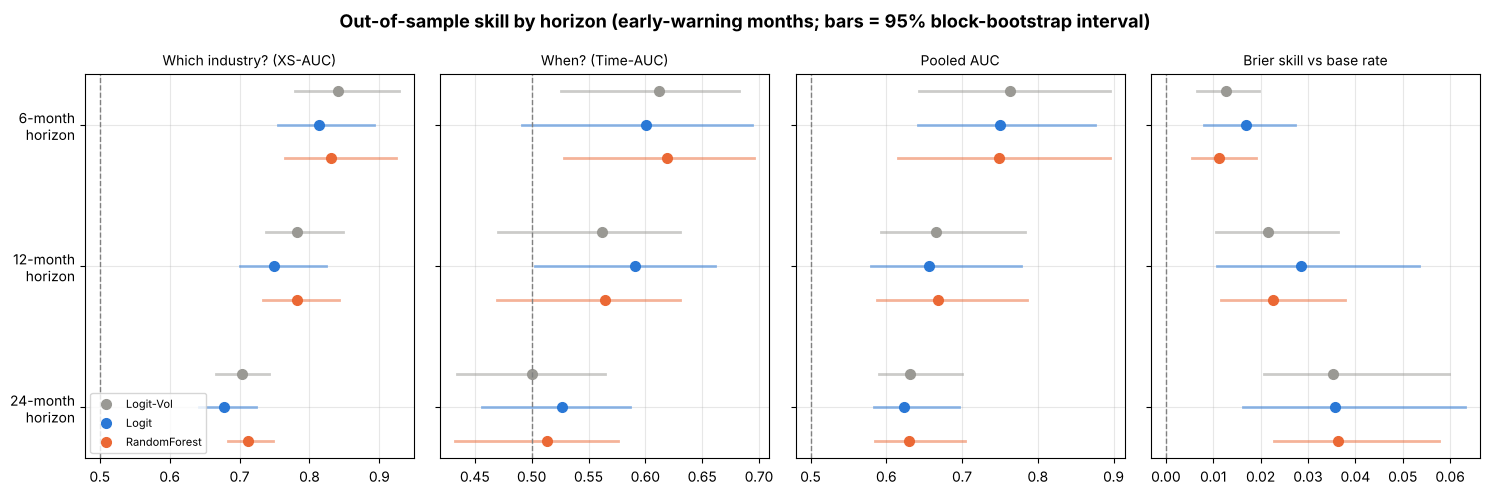

In [29]:
PANELS = [("XS-AUC", 0.5, "Which industry? (XS-AUC)"), ("Time-AUC", 0.5, "When? (Time-AUC)"),
          ("AUC", 0.5, "Pooled AUC"), ("BSS", 0.0, "Brier skill vs base rate")]
ypos = {(H, m): -(i * (len(MODELS) + 1.2) + j) for i, H in enumerate(H_LIST) for j, m in enumerate(MODELS)}
fig, axes = plt.subplots(1, 4, figsize=(15, 5), sharey=True)
fig.suptitle("Out-of-sample skill by horizon (early-warning months; bars = 95% block-bootstrap interval)", fontsize=13, fontweight="bold")
for ax, (metric, ref, title) in zip(axes, PANELS):
    for (H, m), y in ypos.items():
        r = results[H].loc[m]
        ax.plot([r[f"{metric} lo"], r[f"{metric} hi"]], [y, y], color=MODEL_COLORS[m], lw=2, alpha=0.5)
        ax.plot(r[metric], y, "o", color=MODEL_COLORS[m], ms=7, label=m if H == H_LIST[0] else None)
    ax.axvline(ref, color="gray", ls="--", lw=1)
    ax.set_title(title, fontsize=10)
    ax.grid(True, alpha=0.3)
axes[0].set_yticks([np.mean([ypos[(H, m)] for m in MODELS]) for H in H_LIST])
axes[0].set_yticklabels([f"{H}-month\nhorizon" for H in H_LIST])
axes[0].legend(loc="lower left", fontsize=8)
plt.tight_layout()
save(fig, "ranking_scorecard")

## 6.3 Four risk levels and their historical severe-drawdown rate
* **Purpose:** Turn the ranking into the four levels shown to the user, and check that the levels mean something.
* **Method:** Each month, industries that are not already falling are split into quartiles of the ranking: Low, Normal, Elevated, High. Quartiles were fixed in advance; no threshold is fitted or tuned on test results. The table gives the share of industry-months in each level that were followed by a relative drawdown of at least 30% within 24 months, with the sample size and a block-bootstrap interval. The levels are useful only if the rates rise from Low to High.
* **How to read a level:** *Risk levels represent relative downside-risk rankings across industries at each monthly assessment date, rather than absolute measures of market risk.* A quarter of the industries is always "High", even in a calm market. The rates are historical, out-of-sample frequencies and are not guaranteed future outcomes.

In [30]:
LV = PRED[MAIN_H].copy()
LV["Level"], LV["Rank"] = risk_level(LV)
LV["Level (vol-only)"], _ = risk_level(LV, VOL_MODEL)
T = LV[LV["y"].notna() & LV["Level"].notna()].sort_index()                     # rated rows with a known outcome
y, code = T["y"].values, T["Level"].cat.codes.values
by_level = lambda ix: [y[ix][code[ix] == j].mean() for j in range(4)]
pt, lo, hi, draws = month_boot(T, by_level)
level_table = pd.DataFrame({"Industry-months": np.bincount(code, minlength=4), "Severe drawdowns": np.bincount(code, weights=y, minlength=4).astype(int),
                            "Rate 24M": pt, "95% lo": lo, "95% hi": hi, "x overall rate": pt / y.mean()}, index=LEVELS)
for H in (6, 12):
    q = PRED[H].assign(Level=risk_level(PRED[H])[0])
    level_table[f"Rate {H}M"] = q[q["y"].notna()].groupby("Level", observed=False)["y"].mean()
LEVEL_RATE = level_table[["Rate 24M", "95% lo", "95% hi", "Industry-months"]]
t_dates = T.index.get_level_values("Date")
level_facts = pd.Series({"Assessment months with a known outcome": f"{t_dates.min():%Y-%m} to {t_dates.max():%Y-%m}",
                         "Overall severe-drawdown rate (24M)": round(y.mean(), 3),
                         "Bootstrap draws in which the rate rises at every step, Low to High": f"{(np.diff(draws, axis=1) > 0).all(axis=1).mean():.0%}"},
                        name="Value", dtype=object).to_frame()
display(level_table.round(3), level_facts)

,Industry-months,Severe drawdowns,Rate 24M,95% lo,95% hi,x overall rate,Rate 6M,Rate 12M
Low,6858,510,0.074,0.032,0.111,0.567,0.002,0.018
Normal,7203,718,0.100,0.060,0.135,0.760,0.003,0.021
Elevated,7038,872,0.124,0.084,0.168,0.944,0.005,0.028
High,7404,1640,0.222,0.178,0.262,1.688,0.016,0.071


,Value
Assessment months with a known outcome,1960-01 to 2024-09
Overall severe-drawdown rate (24M),0.131
"Bootstrap draws in which the rate rises at every step, Low to High",99%


## 6.4 Stability over time
* **Purpose:** Check that the levels separate risk in every era, and show how much the rates themselves move.
* **Method:** The same rates by 20-year period, with the number of industry-months, and the ranking skill (XS-AUC) of each period. The chart shows the rate of each level over rolling 10-year windows. The ordering should hold in every period; the height of the rates is expected to change with market conditions, which is why a level is a relative statement.

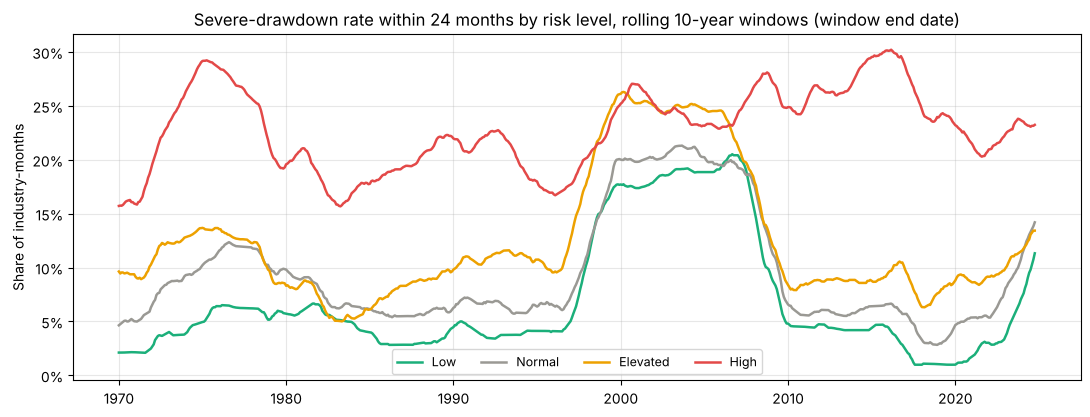

Level,Low,Normal,Elevated,High,Industry-months,Severe drawdowns,XS-AUC,Rates rise Low to High
Period,,,,,,,,
1960–1979,0.040,0.074,0.089,0.178,8275,798,0.717,True
1980–1999,0.112,0.133,0.182,0.236,9658,1609,0.683,True
2000–2024,0.067,0.090,0.098,0.243,10570,1333,0.733,True


In [31]:
T["Period"] = pd.cut(t_dates.year, [1959, 1979, 1999, 2100], labels=["1960–1979", "1980–1999", "2000–2024"])
period_rate = T.groupby(["Period", "Level"], observed=False)["y"].mean().unstack("Level")
period_table = period_rate.assign(**{"Industry-months": T.groupby("Period", observed=False).size(),
                                     "Severe drawdowns": T.groupby("Period", observed=False)["y"].sum().astype(int),
                                     "XS-AUC": [xs_auc(g, MAIN_MODEL).mean() for _, g in T.groupby("Period", observed=False)],
                                     "Rates rise Low to High": (period_rate.diff(axis=1).iloc[:, 1:] > 0).all(axis=1)})
monthly = T.groupby(["Date", "Level"], observed=False)["y"].agg(["sum", "size"]).unstack("Level")
rolling = monthly["sum"].rolling(120, min_periods=120).sum() / monthly["size"].rolling(120, min_periods=120).sum()
fig, ax = plt.subplots(figsize=(13, 4.5))
for lvl, c in zip(LEVELS, ["#1baf7a", "#9a9994", "#eda100", "#e34948"]):
    ax.plot(rolling[lvl], color=c, lw=1.8, label=lvl)
ax.set(title="Severe-drawdown rate within 24 months by risk level, rolling 10-year windows (window end date)", ylabel="Share of industry-months")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
ax.legend(ncol=4, fontsize=9)
ax.grid(True, alpha=0.3)
save(fig, "risk_levels_over_time")
period_table.round(3)

## 6.5 Benchmark: does the model add anything to a volatility ranking?
* **Purpose:** Compare the Random Forest with the traditional risk measure a client already has: ranking industries by volatility.
* **Method:** Four tests at 24 months, all on identical rows.
    1. Ranking skill of each model against the volatility-only Logit, for both targets (ΔXS-AUC with interval).
    2. The same four levels built from the volatility-only ranking: is the High level of the Random Forest riskier than the High level of the volatility ranking?
    3. Ranking skill **inside** each volatility third. If the model only ranks volatility, XS-AUC inside a third falls towards 0.5.
    4. High-level industry-months against non-High ones with a similar past return and volatility (5 × 5 bins).
* **Reading:** an interval that contains 0 means no evidence of added value over the volatility ranking. The product claim is limited to what these tests support.

In [32]:
vol_rows = []
for label, df in [(f"Relative drawdown >= {REL_DD:.0%} (Risk Ranking)", EW[MAIN_H]), (f"Absolute drawdown >= {ABS_DD:.0%}", EW_ABS)]:
    res = evaluate(df, MODELS)
    for m in MODELS:
        row = {"Target": label, "Model": m, **res.loc[m, ["XS-AUC", "XS-AUC lo", "XS-AUC hi"]].to_dict()}
        if m != VOL_MODEL:
            d = paired_diff(df, m, VOL_MODEL)
            row.update({"ΔXS-AUC vs Logit-Vol": d["ΔXS-AUC"], "Δ lo": d["ΔXS-AUC lo"], "Δ hi": d["ΔXS-AUC hi"]})
        vol_rows.append(row)
vol_test = pd.DataFrame(vol_rows).set_index(["Target", "Model"])

Tv = T[T["Level (vol-only)"].notna()]
yv, c_rf, c_vol = Tv["y"].values, Tv["Level"].cat.codes.values, Tv["Level (vol-only)"].cat.codes.values
stat = lambda ix: [yv[ix][c_rf[ix] == 3].mean(), yv[ix][c_vol[ix] == 3].mean(), yv[ix][c_rf[ix] == 3].mean() - yv[ix][c_vol[ix] == 3].mean(),
                   yv[ix][c_rf[ix] == 0].mean(), yv[ix][c_vol[ix] == 0].mean(), yv[ix][c_rf[ix] == 0].mean() - yv[ix][c_vol[ix] == 0].mean()]
pt, lo, hi, _ = month_boot(Tv, stat)
level_vs_vol = pd.DataFrame({"Rate": pt, "95% lo": lo, "95% hi": hi},
                            index=[f"High level — {MAIN_MODEL}", "High level — volatility ranking", "High level — difference",
                                   f"Low level — {MAIN_MODEL}", "Low level — volatility ranking", "Low level — difference"])
level_vs_vol.loc["Share of High-level rows that are also High in the volatility ranking", "Rate"] = (c_vol[c_rf == 3] == 3).mean()

vol6_r = panel["Vol6_R"].reindex(EW[MAIN_H].index)
rows = []
for name, sel in {"Low volatility third": vol6_r <= 1 / 3, "Middle third": (vol6_r > 1 / 3) & (vol6_r <= 2 / 3), "High volatility third": vol6_r > 2 / 3}.items():
    res = evaluate(EW[MAIN_H][sel], MODELS)
    for m in MODELS:
        rows.append({"Volatility group": name, "Model": m, **res.loc[m, ["N", "Crash rate", "XS-AUC", "XS-AUC lo", "XS-AUC hi"]].to_dict()})
within_vol = pd.DataFrame(rows).set_index(["Volatility group", "Model"]).astype({"N": int}).rename(columns={"Crash rate": "Severe-drawdown rate"})

def matched_control(df, flag):
    """Flagged rows against non-flagged rows in the same bin of 24M return (5) x volatility rank (5)."""
    d = df.join(panel["Vol6_R"]).assign(flag=flag).dropna(subset=["y", "R24", "Vol6_R", "flag"]).sort_index()
    y, a = d["y"].values, d["flag"].values.astype(bool)
    b = (5 * pd.qcut(d["R24"], 5, labels=False) + pd.cut(d["Vol6_R"], 5, labels=False)).values
    def stat(ix):
        yy, aa, bb = y[ix], a[ix], b[ix]
        ctrl = pd.Series(yy[~aa]).groupby(bb[~aa]).mean().reindex(bb[aa]).values
        has = np.isfinite(ctrl)
        return [yy[aa][has].mean(), ctrl[has].mean(), yy[aa][has].mean() - ctrl[has].mean()]
    pt, lo, hi, _ = month_boot(d, stat)
    return {"Flagged rows": int(a.sum()), "Rate when flagged": pt[0], "Matched control": pt[1], "Difference": pt[2], "Diff lo": lo[2], "Diff hi": hi[2]}

control_table = pd.DataFrame({f"High level — {MAIN_MODEL}": matched_control(T, T["Level"] == "High"),
                              "High level — volatility ranking": matched_control(Tv, Tv["Level (vol-only)"] == "High")}).T.astype({"Flagged rows": int})
display(vol_test.round(3), level_vs_vol.round(3), within_vol.round(3), control_table.round(3))

XS-AUC  XS-AUC lo  XS-AUC hi  ΔXS-AUC vs Logit-Vol   Δ lo   Δ hi
Target                                  Model                                                                         
Relative drawdown >= 30% (Risk Ranking) Logit-Vol      0.703      0.666      0.742                   NaN    NaN    NaN
                                        Logit          0.677      0.643      0.724                -0.026 -0.048  0.000
                                        RandomForest   0.712      0.683      0.748                 0.009 -0.016  0.043
Absolute drawdown >= 40%                Logit-Vol      0.760      0.688      0.820                   NaN    NaN    NaN
                                        Logit          0.737      0.678      0.802                -0.023 -0.045  0.003
                                        RandomForest   0.740      0.674      0.798                -0.020 -0.036  0.002

,Rate,95% lo,95% hi
High level — RandomForest,0.222,0.178,0.262
High level — volatility ranking,0.232,0.180,0.276
High level — difference,-0.010,-0.025,0.007
Low level — RandomForest,0.074,0.032,0.111
Low level — volatility ranking,0.078,0.034,0.119
Low level — difference,-0.004,-0.019,0.011
Share of High-level rows that are also High in the volatility ranking,0.688,NaN,NaN


N  Severe-drawdown rate  XS-AUC  XS-AUC lo  XS-AUC hi
Volatility group      Model                                                                 
Low volatility third  Logit-Vol     9875                 0.082   0.592      0.519      0.685
                      Logit         9875                 0.082   0.562      0.490      0.652
                      RandomForest  9875                 0.082   0.601      0.537      0.660
Middle third          Logit-Vol     9730                 0.105   0.557      0.490      0.621
                      Logit         9730                 0.105   0.526      0.473      0.591
                      RandomForest  9730                 0.105   0.589      0.537      0.654
High volatility third Logit-Vol     8898                 0.214   0.677      0.635      0.715
                      Logit         8898                 0.214   0.637      0.601      0.685
                      RandomForest  8898                 0.214   0.678      0.636      0.716

,Flagged rows,Rate when flagged,Matched control,Difference,Diff lo,Diff hi
High level — RandomForest,7404,0.222,0.145,0.077,0.038,0.118
High level — volatility ranking,7404,0.232,0.139,0.093,0.043,0.133


## 6.6 How often do levels change?
* **Purpose:** Check that a level is stable enough to act on, and find out how many High signals are short-lived.
* **Method:** Month-to-month transition matrix of the levels of the same industry, the length of spells at the High level, and the rank correlation of the ranking with itself 1, 3 and 12 months later.

In [33]:
lv = LV["Level"].unstack("Industry")                                           # month x industry; missing when already falling
pairs = pd.DataFrame({"This month": lv.stack(), "Next month": lv.shift(-1).stack()}).dropna()
transition = pd.crosstab(pairs["This month"], pairs["Next month"], normalize="index").reindex(index=LEVELS, columns=LEVELS)
is_high = lv.eq("High")
spells = np.array([len(g) for c in is_high for _, g in is_high[c].groupby((is_high[c] != is_high[c].shift()).cumsum()) if g.iloc[0]])
rk = LV["Rank"].unstack("Industry")
stability = pd.Series({"Same level next month": (pairs["This month"] == pairs["Next month"]).mean(),
                       "Moves two or more levels in one month": (abs(pairs["This month"].cat.codes - pairs["Next month"].cat.codes) >= 2).mean(),
                       "High spells lasting one month only": (spells == 1).mean(),
                       "Median length of a High spell (months)": np.median(spells),
                       **{f"Rank correlation with the ranking {k} months later": rk.corrwith(rk.shift(-k), axis=1, method="spearman").mean() for k in (1, 3, 12)}},
                      name="Value").to_frame()
display(transition.round(3), stability.round(3))

Next month,Low,Normal,Elevated,High
This month,,,,
Low,0.810,0.158,0.028,0.004
Normal,0.149,0.662,0.170,0.019
Elevated,0.029,0.172,0.654,0.145
High,0.003,0.019,0.140,0.839


,Value
Same level next month,0.741
Moves two or more levels in one month,0.025
High spells lasting one month only,0.401
Median length of a High spell (months),2.000
Rank correlation with the ranking 1 months later,0.896
Rank correlation with the ranking 3 months later,0.802
Rank correlation with the ranking 12 months later,0.614


## 6.7 Should a High signal be confirmed before it is shown?
* **Purpose:** Compare signal rules before adopting one. A confirmation rule removes short-lived signals but warns later.
* **Method:** Four rules are scored on the same history.

| Rule | Condition |
|---|---|
| A | High this month |
| B | High two months in a row |
| C | High or Elevated in at least 2 of the last 3 months |
| D | High in at least 2 of the last 3 months |

An **event** is the first month an industry is 30% below its 24-month high relative to the market (a new event needs more than 24 months since the last one). For each rule: the share of industry-months flagged, the severe-drawdown rate and false-alarm rate of flagged months, the share of events flagged at least once in the 24 months before the event, the median lead time, and the extra wait compared with rule A.

In [34]:
def drawdown_events(px, dd):
    below = px / px.rolling(24, min_periods=1).max() - 1 <= -dd
    out = []
    for ind in px.columns:
        last = None
        for d in below.index[below[ind].fillna(False)]:
            if last is None or (d.to_period("M") - last.to_period("M")).n > 24:
                out.append((ind, d))
                last = d
    return pd.DataFrame(out, columns=["Industry", "Onset"])

near = lv.isin(["Elevated", "High"])
RULES = {"A: High this month": is_high,
         "B: High two months in a row": is_high & is_high.shift(1, fill_value=False),
         "C: High or Elevated in 2 of the last 3 months": near.astype(int).rolling(3, min_periods=1).sum() >= 2,
         "D: High in 2 of the last 3 months": is_high.astype(int).rolling(3, min_periods=1).sum() >= 2}
Yw = LV["y"].unstack("Industry")
events = drawdown_events(rel_px, REL_DD)
events = events[(events["Onset"] >= lv.index[0] + pd.DateOffset(months=MAIN_H)) & events["Industry"].isin(lv.columns)]

def first_signal(sig, ind, onset):
    w = sig[ind].loc[onset - pd.DateOffset(months=MAIN_H):onset - pd.DateOffset(months=1)]
    return w[w].index.min() if w.any() else pd.NaT

first_a = [first_signal(RULES["A: High this month"], i, d) for i, d in zip(events["Industry"], events["Onset"])]
rows = {}
for name, sig in RULES.items():
    rated = lv.notna()
    sig = sig & rated
    hit = Yw.where(sig).stack()
    first = [first_signal(sig, i, d) for i, d in zip(events["Industry"], events["Onset"])]
    lead = [(d.to_period("M") - f.to_period("M")).n for d, f in zip(events["Onset"], first) if pd.notna(f)]
    wait = [(f.to_period("M") - a.to_period("M")).n for f, a in zip(first, first_a) if pd.notna(f) and pd.notna(a)]
    rows[name] = {"Industry-months flagged": sig.sum().sum() / rated.sum().sum(), "Severe-drawdown rate when flagged": hit.mean(),
                  "False-alarm rate": 1 - hit.mean(), "Events": len(events), "Events flagged in advance": len(lead) / len(events),
                  "Median lead time (months)": np.median(lead), "Mean extra wait vs rule A (months)": np.mean(wait)}
rule_table = pd.DataFrame(rows).T.astype({"Events": int})
rule_table.round(3)

,Industry-months flagged,Severe-drawdown rate when flagged,False-alarm rate,Events,Events flagged in advance,Median lead time (months),Mean extra wait vs rule A (months)
A: High this month,0.260,0.222,0.778,340,0.544,23.0,0.000
B: High two months in a row,0.207,0.234,0.766,340,0.485,23.0,1.255
C: High or Elevated in 2 of the last 3 months,0.489,0.175,0.825,340,0.685,24.0,-0.989
D: High in 2 of the last 3 months,0.245,0.225,0.775,340,0.497,24.0,0.929


# Part 7 — Core 2: Run-up Watch

## 7.1 Run-up episodes and their outcome
* **Purpose:** Measure how often a sharp price run-up was followed by a severe drawdown, counting each run-up once.
* **Method:** The run-up rule is the one of Greenwood, Shleifer & You (2019), taken from the paper and not tuned here: a 24-month return of at least 100%, both raw and net of the market, and a 60-month return of at least 50%, in an industry with at least 10 firms. An **episode** starts in the first flagged month; a new episode needs more than 24 months since the last flagged month. The outcome is the Run-up Watch target (absolute drawdown ≥ 40% within 24 months of the first flagged month).
    * Counting every flagged month would count the same run-up many times and overstate the rate; the table shows both numbers so the size of that bias is visible.
    * Two intervals are given: a Wilson interval, and a bootstrap that resamples whole calendar years, because run-ups in the same year are not independent.
    * **Baseline: a matched control, counted per episode.** Each episode is compared with the other industries in the **same month** that are not in a run-up and not already falling, scored on the same target over the same 24 months. This keeps the unit the same (one start month and one 24-month outcome per industry) and removes the effect of time: run-ups and severe drawdowns both cluster in a few periods, so a comparison with the rate over all industry-months would mix units and mix eras.
* **Wording:** this is a *historical run-up risk pattern with limited out-of-sample validation* (7.3), not a proven early-warning signal.

In [35]:
def runup_flag(x):
    return (R24 >= x) & (Net24 >= x) & (R60 >= RUNUP_5Y) & eligible

def runup_episodes(flag):
    out = []
    for ind in INDS:
        last = None
        for d in flag.index[flag[ind]]:
            if last is None or (d.to_period("M") - last.to_period("M")).n > 24:
                out.append((ind, d))
            last = d
    return pd.DataFrame(out, columns=["Industry", "Date"])

def episode_outcomes(ep):
    """Outcome of each episode with a complete 24-month future window."""
    rows = []
    for ind, d in zip(ep["Industry"], ep["Date"]):
        px = price[ind].loc[d:].iloc[:MAIN_H + 1]
        if len(px) <= MAIN_H or px.isna().any():
            continue
        m = (1 + mkt.loc[d:].iloc[1:MAIN_H + 1]).cumprod()
        rows.append({"Industry": ind, "Date": d, "Severe drawdown": CRASH_ABS.at[d, ind],
                     "Months to peak": (px.idxmax().to_period("M") - d.to_period("M")).n, "Return to peak": px.max() / px.iloc[0] - 1,
                     "Return 12M": px.iloc[12] / px.iloc[0] - 1, "Return 24M": px.iloc[-1] / px.iloc[0] - 1,
                     "Return 24M net of market": px.iloc[-1] / px.iloc[0] - m.iloc[-1]})
    return pd.DataFrame(rows)

def wilson(k, n, z=1.96):
    p, d = k / n, 1 + z * z / n
    c, h = p + z * z / (2 * n), z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n))
    return (c - h) / d, (c + h) / d

def year_cluster(e, values, seed=SEED, n_boot=2000):
    """Bootstrap draws of the mean of `values` that resample whole calendar years (episodes in one year are not independent)."""
    rng, years = np.random.default_rng(seed), e["Date"].dt.year.values
    uniq = np.unique(years)
    return np.array([values[np.concatenate([np.flatnonzero(years == yr) for yr in rng.choice(uniq, len(uniq))])].mean() for _ in range(n_boot)])

def matched_control(ep, flag):
    """For each episode: severe-drawdown rate of the other eligible industries in the same month that are not in a run-up
    and not already falling. Same start month and same 24-month target, so each episode gets a like-for-like baseline."""
    rates = []
    for ind, d in zip(ep["Industry"], ep["Date"]):
        peers = eligible.loc[d] & ~flag.loc[d] & (W["DD12"].loc[d] > MASK_DD12)
        rates.append(CRASH_ABS.loc[d].where(peers).drop(ind).mean())
    return np.array(rates)

def with_control(ep, flag):
    e = episode_outcomes(ep)
    e["Matched control"] = matched_control(e, flag)
    assert e["Matched control"].notna().all(), "every episode needs at least one control industry"
    e["Difference"] = e["Severe drawdown"] - e["Matched control"]
    return e

strict = runup_flag(RUNUP_2Y)
EP = with_control(runup_episodes(strict), strict)
k, n = int(EP["Severe drawdown"].sum()), len(EP)
rate_lo, rate_hi = np.percentile(year_cluster(EP, EP["Severe drawdown"].values), [2.5, 97.5])
diff_lo, diff_hi = np.percentile(year_cluster(EP, EP["Difference"].values), [2.5, 97.5])
runup_facts = pd.Series({
    "Flagged industry-months": int(strict.sum().sum()),
    "Episodes": len(runup_episodes(strict)),
    "Episodes with a complete 24-month outcome": n,
    "Distinct industries / calendar years": f"{EP['Industry'].nunique()} / {EP['Date'].dt.year.nunique()}",
    "Episodes followed by a severe drawdown": k,
    "Rate, counted per episode": round(k / n, 3),
    "Wilson 95% interval": "[{:.3f}, {:.3f}]".format(*wilson(k, n)),
    "Year-clustered bootstrap 95% interval": f"[{rate_lo:.3f}, {rate_hi:.3f}]",
    "Matched control: other industries in the same months": round(EP["Matched control"].mean(), 3),
    "Difference, episode minus matched control": round(EP["Difference"].mean(), 3),
    "Difference, year-clustered 95% interval": f"[{diff_lo:.3f}, {diff_hi:.3f}]",
    "For comparison: rate counted per flagged month (overstated by overlap)": round(CRASH_ABS.where(strict).stack().mean(), 3)},
    name="Value", dtype=object).to_frame()
runup_facts


,Value
Flagged industry-months,334
Episodes,48
Episodes with a complete 24-month outcome,46
Distinct industries / calendar years,24 / 28
Episodes followed by a severe drawdown,19
"Rate, counted per episode",0.413
Wilson 95% interval,"[0.283, 0.557]"
Year-clustered bootstrap 95% interval,"[0.213, 0.592]"
Matched control: other industries in the same months,0.16
"Difference, episode minus matched control",0.253


## 7.2 Does a larger run-up carry more risk?
* **Purpose:** Check that the pattern is graded: the larger the run-up, the more often a severe drawdown followed, compared with similar industries at the same time.
* **Method:** The same episode count for five thresholds, each with its matched control (7.1) and intervals. Three cautions apply.
    * **The groups are nested.** Every ≥150% episode is also in the ≥125% group, and so on. The five rows are one pattern seen at five cut-offs, not five independent pieces of evidence.
    * **Multiple testing.** For each threshold the difference between the episodes and their matched controls is tested with a one-sided bootstrap that resamples whole calendar years, and the p-values are adjusted with the Benjamini–Hochberg method.
    * **No threshold is picked for its result.** The 100% rule is used because it was fixed in the paper before this analysis; the highest thresholds have the fewest episodes and the widest intervals.


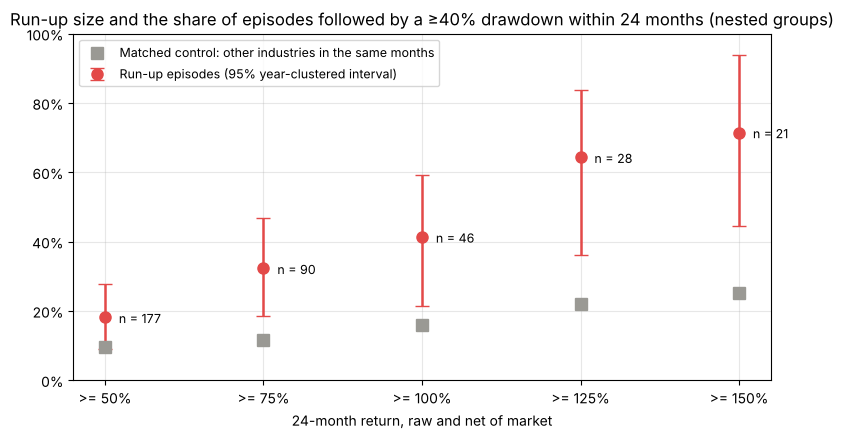

,Episodes,Severe drawdowns,Rate,Wilson lo,Wilson hi,Year-cluster lo,Year-cluster hi,Matched control,Difference,Diff lo,Diff hi,p (difference <= 0),p adjusted (BH),Mean return 24M net of market,Median return 24M net of market
Run-up threshold,,,,,,,,,,,,,,,
>= 50%,177,32,0.181,0.131,0.244,0.090,0.278,0.096,0.085,0.030,0.142,0.001,0.001,0.041,-0.034
>= 75%,90,29,0.322,0.235,0.424,0.184,0.469,0.116,0.206,0.093,0.321,0.000,0.001,0.020,-0.037
>= 100%,46,19,0.413,0.283,0.557,0.213,0.592,0.160,0.253,0.092,0.392,0.000,0.001,-0.022,-0.125
>= 125%,28,18,0.643,0.458,0.793,0.360,0.838,0.221,0.422,0.181,0.583,0.000,0.001,-0.151,-0.160
>= 150%,21,15,0.714,0.500,0.862,0.444,0.938,0.251,0.463,0.287,0.615,0.000,0.001,-0.183,-0.214


In [36]:
rows = []
for x in RUNUP_GRID:
    flag = runup_flag(x)
    e = with_control(runup_episodes(flag), flag)
    k, n = int(e["Severe drawdown"].sum()), len(e)
    lo_w, hi_w = wilson(k, n)
    lo_c, hi_c = np.percentile(year_cluster(e, e["Severe drawdown"].values), [2.5, 97.5])
    d_draws = year_cluster(e, e["Difference"].values)
    rows.append({"Run-up threshold": f">= {x:.0%}", "Episodes": n, "Severe drawdowns": k, "Rate": k / n, "Wilson lo": lo_w, "Wilson hi": hi_w,
                 "Year-cluster lo": lo_c, "Year-cluster hi": hi_c, "Matched control": e["Matched control"].mean(),
                 "Difference": e["Difference"].mean(), "Diff lo": np.percentile(d_draws, 2.5), "Diff hi": np.percentile(d_draws, 97.5),
                 "p (difference <= 0)": (1 + (d_draws <= 0).sum()) / (1 + len(d_draws)),
                 "Mean return 24M net of market": e["Return 24M net of market"].mean(), "Median return 24M net of market": e["Return 24M net of market"].median()})
runup_table = pd.DataFrame(rows).set_index("Run-up threshold")
runup_table.insert(runup_table.columns.get_loc("p (difference <= 0)") + 1, "p adjusted (BH)",
                   multipletests(runup_table["p (difference <= 0)"], method="fdr_bh")[1])

fig, ax = plt.subplots(figsize=(9, 4.5))
xpos = np.arange(len(runup_table))
ax.errorbar(xpos, runup_table["Rate"], yerr=[runup_table["Rate"] - runup_table["Year-cluster lo"], runup_table["Year-cluster hi"] - runup_table["Rate"]],
            fmt="o", color="#e34948", ms=8, capsize=5, lw=1.8, label="Run-up episodes (95% year-clustered interval)")
ax.plot(xpos, runup_table["Matched control"], "s", color="#9a9994", ms=8, label="Matched control: other industries in the same months")
for x_, (n_, r_) in enumerate(zip(runup_table["Episodes"], runup_table["Rate"])):
    ax.annotate(f"n = {n_}", (x_, r_), xytext=(10, -4), textcoords="offset points", fontsize=9)
ax.set_xticks(xpos)
ax.set_xticklabels(runup_table.index)
ax.set(title="Run-up size and the share of episodes followed by a ≥40% drawdown within 24 months (nested groups)",
       xlabel="24-month return, raw and net of market", ylim=(0, 1))
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
ax.legend(loc="upper left", fontsize=9)
ax.grid(True, alpha=0.3)
save(fig, "runup_watch_thresholds")
runup_table.round(3)


## 7.3 Out-of-sample check: episodes after the paper's sample
* **Purpose:** See whether the pattern holds in data the original study could not have used.
* **Method:** The 100% rule by period. The paper's US sample ends in 2014, so episodes from 2015 are the only true out-of-sample evidence. Each period also shows its matched control. The count is small and its interval is wide; it neither confirms nor rejects the pattern.

In [37]:
EP["Period"] = pd.cut(EP["Date"].dt.year, [1900, 1959, 1989, 2014, 2100], labels=["to 1959", "1960–1989", "1990–2014", "2015 onwards (out of sample)"])
runup_periods = EP.groupby("Period", observed=False)["Severe drawdown"].agg(Episodes="size", Drawdowns="sum").astype(int)
runup_periods["Rate"] = runup_periods["Drawdowns"] / runup_periods["Episodes"]
runup_periods[["Wilson lo", "Wilson hi"]] = [wilson(k, n) for k, n in zip(runup_periods["Drawdowns"], runup_periods["Episodes"])]
runup_periods["Matched control"] = EP.groupby("Period", observed=False)["Matched control"].mean()
recent = EP.loc[EP["Date"].dt.year >= 2015, ["Industry", "Date", "Severe drawdown", "Matched control", "Return 24M", "Return 24M net of market"]].assign(
    Date=lambda d: d["Date"].dt.strftime("%Y-%m")).set_index("Industry")
display(runup_periods.round(3), recent.round(2))

,Episodes,Drawdowns,Rate,Wilson lo,Wilson hi,Matched control
Period,,,,,,
to 1959,7,4,0.571,0.250,0.842,0.403
1960–1989,19,8,0.421,0.231,0.637,0.115
1990–2014,13,6,0.462,0.232,0.709,0.148
2015 onwards (out of sample),7,1,0.143,0.026,0.513,0.063


,Date,Severe drawdown,Matched control,Return 24M,Return 24M net of market
Industry,,,,,
Toys,2020-12,1.0,0.12,-0.67,-0.66
Fun,2018-06,0.0,0.12,-0.07,-0.24
Cnstr,2024-09,0.0,0.00,0.22,-0.14
Steel,2022-02,0.0,0.03,0.36,0.18
Autos,2020-08,0.0,0.09,0.55,0.41
Mines,2022-03,0.0,0.03,0.25,0.06
Oil,2022-05,0.0,0.04,0.14,-0.18


## 7.4 What happened after the signal?
* **Purpose:** Show what an investor would have lived through after a run-up was flagged.
* **Method:** Averages over episodes, split by outcome: months until the price peak, the return up to that peak, and the 12- and 24-month returns. Prices usually kept rising after the signal, so the flag supports a review of position size; it is not a signal to sell or to short.

In [38]:
after = pd.DataFrame({name: {"Episodes": len(g_), "Months to peak (mean)": g_["Months to peak"].mean(), "Months to peak (median)": g_["Months to peak"].median(),
                             "Return to peak": g_["Return to peak"].mean(), "Return 12M": g_["Return 12M"].mean(), "Return 24M": g_["Return 24M"].mean(),
                             "Return 24M net of market": g_["Return 24M net of market"].mean()}
                      for name, g_ in [("All episodes", EP), ("Followed by a severe drawdown", EP[EP["Severe drawdown"] == 1]),
                                       ("Not followed by one", EP[EP["Severe drawdown"] == 0])]}).T.astype({"Episodes": int})
after.round(2)

,Episodes,Months to peak (mean),Months to peak (median),Return to peak,Return 12M,Return 24M,Return 24M net of market
All episodes,46,12.37,12.5,0.44,0.08,0.05,-0.02
Followed by a severe drawdown,19,5.32,3.0,0.25,-0.10,-0.42,-0.33
Not followed by one,27,17.33,18.0,0.58,0.20,0.38,0.20


## 7.5 Can the ranking model tell which run-ups end badly?
* **Purpose:** Test whether the Risk Ranking adds information inside a run-up.
* **Method:** Ranking skill of each model on the industry-months inside a strict run-up, for the Run-up Watch target. The sample is small and the models see very few run-up rows in training (4.4), so an interval that contains 0.5 means the question cannot be answered. Run-up Watch and the Risk Ranking are therefore shown as two separate signals.

In [39]:
in_runup = evaluate(EW_ABS[EW_ABS["RunUp"] == 1], MODELS)[["N", "Crash rate", "XS-AUC", "AUC", "AUC lo", "AUC hi"]].rename(columns={"Crash rate": "Severe-drawdown rate"})
in_runup.round(3)

,N,Severe-drawdown rate,XS-AUC,AUC,AUC lo,AUC hi
Logit-Vol,269,0.55,0.433,0.271,0.101,0.448
Logit,269,0.55,0.267,0.199,0.087,0.364
RandomForest,269,0.55,0.267,0.314,0.084,0.551


# Part 8 — Core 3: Portfolio Exposure Review

## 8.1 Exposure of a portfolio by risk level
* **Purpose:** Show a client where their own portfolio sits in the ranking and which holdings to review.
* **Method:** The client supplies industry weights. The function returns the weight in each risk level, next to the cap-weighted market for comparison, and the holdings that are High or inside a run-up. The portfolio below is **illustrative**, not a client portfolio and not a test result.
    * This is **exposure**, not risk contribution: 15% in High means 15% of the money is in industries ranked High, not that 15% of the portfolio's risk comes from them.
    * No portfolio score or probability of a portfolio loss is produced. A weighted score was tested and was weaker than a plain volatility score (11.5).
    * Holdings must be mapped to the 48 Fama–French industries first; firms with several lines of business may not map cleanly.

In [40]:
runup_size = sum(runup_flag(x).astype(int) for x in RUNUP_GRID)                                      # number of thresholds passed
RUNUP_LABEL = runup_size.replace(dict(enumerate(["—"] + [f">= {x:.0%}" for x in RUNUP_GRID])))
months_high = is_high.apply(lambda s: s.astype(int).groupby((~s).cumsum()).cumsum())                 # consecutive months at High
STATUS = pd.DataFrame(np.select([months_high >= 2, months_high == 1], ["Confirmed", "Watch"], default="—"), index=lv.index, columns=lv.columns)

def exposure_review(weights, date):
    w = pd.Series(weights, dtype=float)
    w = w / w.sum()
    level = lv.loc[date].astype(object).reindex(w.index).fillna("Already falling")
    holdings = pd.DataFrame({"Weight": w, "Risk level": level, "High status": STATUS.loc[date].reindex(w.index),
                             "Run-up": RUNUP_LABEL.loc[date].reindex(w.index)})
    cap = LV["MCap"].xs(date, level="Date")
    market = (cap / cap.sum()).groupby(lv.loc[date].astype(object).fillna("Already falling")).sum()
    summary = pd.DataFrame({"Portfolio": w.groupby(level).sum(), "Market (cap-weighted)": market}).reindex(LEVELS + ["Already falling"]).fillna(0.0).rename_axis("Risk level")
    review = holdings[(holdings["Risk level"] == "High") | (holdings["Run-up"] != "—")].sort_values("Weight", ascending=False)
    return summary, holdings.sort_values("Weight", ascending=False), review

LAST = lv.index[-1]
EXAMPLE_PORTFOLIO = {"Softw": 0.15, "Chips": 0.15, "Banks": 0.12, "Drugs": 0.12, "Rtail": 0.10,
                     "Oil": 0.08, "Util": 0.08, "Hardw": 0.08, "Autos": 0.06, "Insur": 0.06}
exposure, holdings, review = exposure_review(EXAMPLE_PORTFOLIO, LAST)
print(f"Illustrative portfolio, data as of {LAST:%Y-%m-%d}")
display(exposure.round(3), review.round(3))

Illustrative portfolio, data as of 2026-09-30


,Portfolio,Market (cap-weighted)
Risk level,,
Low,0.10,0.154
Normal,0.35,0.319
Elevated,0.26,0.164
High,0.29,0.304
Already falling,0.00,0.060


,Weight,Risk level,High status,Run-up
Chips,0.15,High,Confirmed,>= 50%
Hardw,0.08,High,Confirmed,>= 100%
Autos,0.06,High,Confirmed,—


# Part 9 — Core 4: Why This Industry Is Flagged

## 9.1 Contributing factors for the latest ranking
* **Purpose:** Tell the user which inputs pushed an industry's ranking up in the latest month.
* **Method:** SHAP values of the Random Forest fitted at the end of last year, for the industries currently at the High level. A positive value raised the score; the three largest are stored as `Key drivers` for the monthly report. These are **contributing factors of the model's output**, not causes of a drawdown, and correlated inputs share credit. An assert checks SHAP additivity.

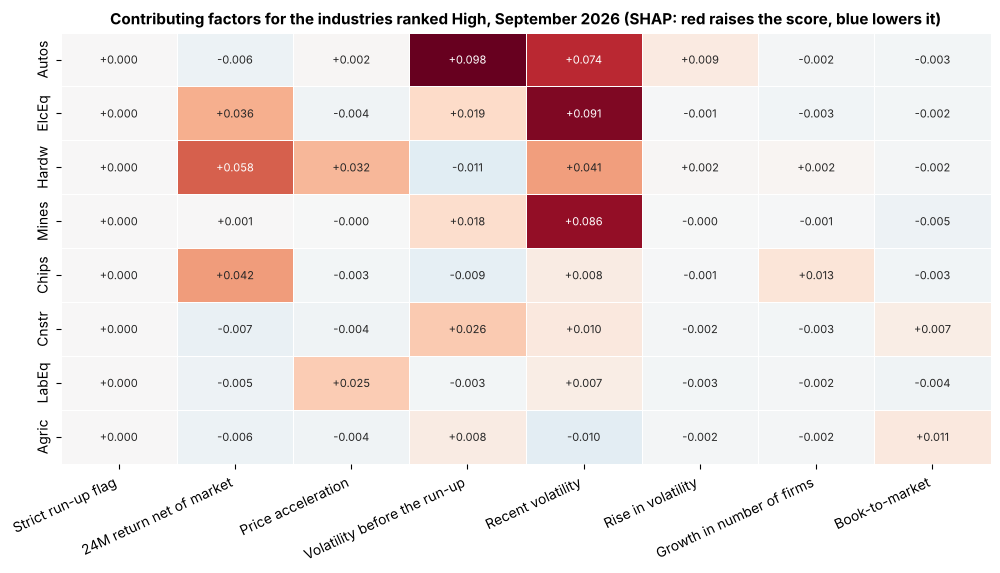

In [41]:
FEAT_LABEL = {"RunUp": "Strict run-up flag", "Net24_R": "24M return net of market", "Accel_R": "Price acceleration", "Vol_pre_R": "Volatility before the run-up",
              "Vol6_R": "Recent volatility", "Vol_Chg_R": "Rise in volatility", "Firms_Chg24_R": "Growth in number of firms", "BM_R": "Book-to-market"}

def shap_values(model, X):
    Xt = model["clip"].transform(X)
    expl = shap.TreeExplainer(model["clf"])
    sv = expl.shap_values(Xt)
    sv = sv[1] if isinstance(sv, list) else (sv[:, :, 1] if np.ndim(sv) == 3 else sv)      # class 1 = severe drawdown
    gap = np.abs(np.atleast_1d(expl.expected_value)[-1] + sv.sum(axis=1) - model["clf"].predict_proba(Xt)[:, 1]).max()
    assert gap < 1e-3, "SHAP additivity failed"
    return pd.DataFrame(sv, index=X.index, columns=X.columns)

now_rows = panel.xs(LAST, level="Date")
now_rows = now_rows[~now_rows["Masked"]]
SV_NOW = shap_values(FITTED[(LAST.year, MAIN_MODEL)], now_rows[FEATS_MAIN]).rename(columns=FEAT_LABEL)
DRIVERS = SV_NOW.apply(lambda r: "; ".join(f"{f} ({v:+.3f})" for f, v in r.nlargest(3).items() if v > 0), axis=1)
high_now = lv.loc[LAST][lv.loc[LAST] == "High"].index
order = LV["Rank"].xs(LAST, level="Date").reindex(high_now).sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(12, 0.45 * len(order) + 2))
sns.heatmap(SV_NOW.loc[order], annot=True, fmt="+.3f", cmap="RdBu_r", center=0, cbar=False, linewidths=0.5, annot_kws={"size": 8}, ax=ax)
ax.set(xlabel="", ylabel="")
ax.set_title(f"Contributing factors for the industries ranked High, {LAST:%B %Y} (SHAP: red raises the score, blue lowers it)", fontsize=11, fontweight="bold")
plt.xticks(rotation=25, ha="right")
save(fig, "why_flagged_latest")

## 9.2 Which inputs matter most over time?
* **Purpose:** Show what the ranking relies on in general, at four different points in history.
* **Method:** Share of mean |SHAP| by feature group for the models fitted before four stress periods, over all industries not already falling in that year.

In [42]:
group_share = {}
for crisis, year in EXPLAIN_YEARS.items():
    rows = panel[(panel["Year"] == year) & ~panel["Masked"]]
    imp = shap_values(FITTED[(year, MAIN_MODEL)], rows[FEATS_MAIN]).abs().mean()
    group_share[crisis] = pd.Series({g: imp[f].sum() for g, f in FEAT_GROUP.items()}) / imp.sum()
shap_group = pd.DataFrame(group_share)
shap_group.round(3)

,Dot-com 2000,GFC 2008,COVID 2020,Rates 2022
Price run-up,0.278,0.283,0.261,0.24
Volatility,0.601,0.612,0.622,0.65
Issuance / valuation,0.120,0.105,0.118,0.11


# Part 10 — Monthly Risk Report

## 10.1 Market context
* **Purpose:** Give the background a user needs to read relative risk levels: is the market as a whole calm or stressed, and is explosive price behaviour widespread?
* **Method:** Supporting information only. The HMM regime and the GSADF flags were tested as predictors and did not improve the ranking (11.2), so they are shown as context and are not signals. The data as-of date is the last month with complete data; the report is monthly and is not real-time monitoring.

In [43]:
gs_now = ind_psy.loc[LAST]
cap_now = LV["MCap"].xs(LAST, level="Date") / LV["MCap"].xs(LAST, level="Date").sum()
context = pd.Series({
    "Data as of": f"{LAST:%Y-%m-%d}",
    "Models fitted on data to": f"{LAST.year - 1}-12-31",
    "Volatility regime (HMM)": regime_m["Regime"].iloc[-1],
    "P(High volatility), monthly average": round(regime_m["High volatility"].iloc[-1], 2),
    "Industries with a GSADF flag (explosive price behaviour)": f"{int(gs_now.sum())} of {int(gs_now.notna().sum())}: {', '.join(gs_now[gs_now == 1].index) or 'none'}",
    f"Industries in a run-up (>= {RUNUP_2Y:.0%})": ", ".join(strict.loc[LAST][strict.loc[LAST]].index) or "none",
    "Industries rated / already falling": f"{int(lv.loc[LAST].notna().sum())} / {int(LV['Masked'].xs(LAST, level='Date').sum())}",
    "High: confirmed / watch": f"{int((STATUS.loc[LAST] == 'Confirmed').sum())} / {int((STATUS.loc[LAST] == 'Watch').sum())}",
    "Industries whose level changed this month": int((lv.loc[LAST].astype(object).fillna("-") != lv.iloc[-2].astype(object).fillna("-")).sum()),
    "Largest industry weight in the market": f"{cap_now.idxmax()} {cap_now.max():.1%}"},
    name=f"Monthly Risk Report — {LAST:%B %Y}", dtype=object).to_frame()
context

,Monthly Risk Report — September 2026
Data as of,2026-09-30
Models fitted on data to,2025-12-31
Volatility regime (HMM),Normal volatility
"P(High volatility), monthly average",0.0
Industries with a GSADF flag (explosive price behaviour),1 of 38: Chips
Industries in a run-up (>= 100%),Hardw
Industries rated / already falling,31 / 7
High: confirmed / watch,6 / 2
Industries whose level changed this month,9
Largest industry weight in the market,Chips 22.8%


## 10.2 Industry table
* **Purpose:** The page a user reads each month: every industry that is High, inside a run-up, or changed level.
* **Method:** For each industry: current and previous level, High status (`Watch` = first month at High, `Confirmed` = two or more months in a row; see 6.7 for the trade-off), the historical severe-drawdown rate of its level with the number of industry-months behind it, run-up size, GSADF flag, key drivers and market weight. *Historical rates are based on past out-of-sample risk classifications and should not be interpreted as guaranteed future outcomes.* The table supports a decision; it is not a recommendation to buy or sell.

In [44]:
snap = LV.xs(LAST, level="Date")
cur, prev = lv.loc[LAST].astype(object), lv.iloc[-2].astype(object)
report = pd.DataFrame({
    "Sector": pd.Series(SECTOR_OF),
    "Risk level": cur.fillna("Already falling"),
    "Previous level": prev.fillna("Already falling"),
    "High status": STATUS.loc[LAST],
    "Months at High": months_high.loc[LAST],
    "Historical rate 24M": cur.map(LEVEL_RATE["Rate 24M"]),
    "Sample size": cur.map(LEVEL_RATE["Industry-months"]).astype("Int64"),
    "Run-up": RUNUP_LABEL.loc[LAST],
    "GSADF flag": gs_now.map({1.0: "Yes", 0.0: "—"}),
    "Key drivers": DRIVERS.replace("", "—"),
    "Market weight": cap_now,
    "Rank": snap["Rank"]}).reindex(snap.index)
show = (report["Risk level"] == "High") | (report["Run-up"] != "—") | (report["Risk level"] != report["Previous level"])
report[show].sort_values("Rank", ascending=False).drop(columns="Rank").fillna({"Key drivers": "—"}).round(3)

,Sector,Risk level,Previous level,High status,Months at High,Historical rate 24M,Sample size,Run-up,GSADF flag,Key drivers,Market weight
Industry,,,,,,,,,,,
Autos,Consumer Discretionary,High,High,Confirmed,2,0.222,7404,—,—,Volatility before the run-up (+0.098); Recent volatility (+0.074); Rise in volatility (+0.009),0.025
ElcEq,Industrials,High,Already falling,Watch,1,0.222,7404,—,—,Recent volatility (+0.091); 24M return net of market (+0.036); Volatility before the run-up (+0.019),0.003
Hardw,Information Technology,High,High,Confirmed,6,0.222,7404,>= 100%,—,24M return net of market (+0.058); Recent volatility (+0.041); Price acceleration (+0.032),0.017
Mines,Materials,High,High,Confirmed,39,0.222,7404,—,—,Recent volatility (+0.086); Volatility before the run-up (+0.018); 24M return net of market (+0.001),0.005
Chips,Information Technology,High,High,Confirmed,7,0.222,7404,>= 50%,Yes,24M return net of market (+0.042); Growth in number of firms (+0.013); Recent volatility (+0.008),0.228
Cnstr,Industrials,High,High,Confirmed,13,0.222,7404,—,—,Volatility before the run-up (+0.026); Recent volatility (+0.010); Book-to-market (+0.007),0.006
LabEq,Information Technology,High,High,Confirmed,2,0.222,7404,—,—,Price acceleration (+0.025); Recent volatility (+0.007),0.018
Agric,Consumer Staples,High,Elevated,Watch,1,0.222,7404,—,—,Book-to-market (+0.011); Volatility before the run-up (+0.008),0.001
Fin,Financials,Elevated,High,—,0,0.124,7038,—,—,Growth in number of firms (+0.020); Book-to-market (+0.001); Price acceleration (+0.001),0.032


## 10.3 Sector view
* **Purpose:** Show where relative risk sits across the 11 sectors and how it moved over five years.
* **Method:** Cap-weighted average of the industries' percentile rank in each sector (0.5 = middle of the ranking). Industries already falling are excluded; a blank cell means every industry of the sector was already falling.

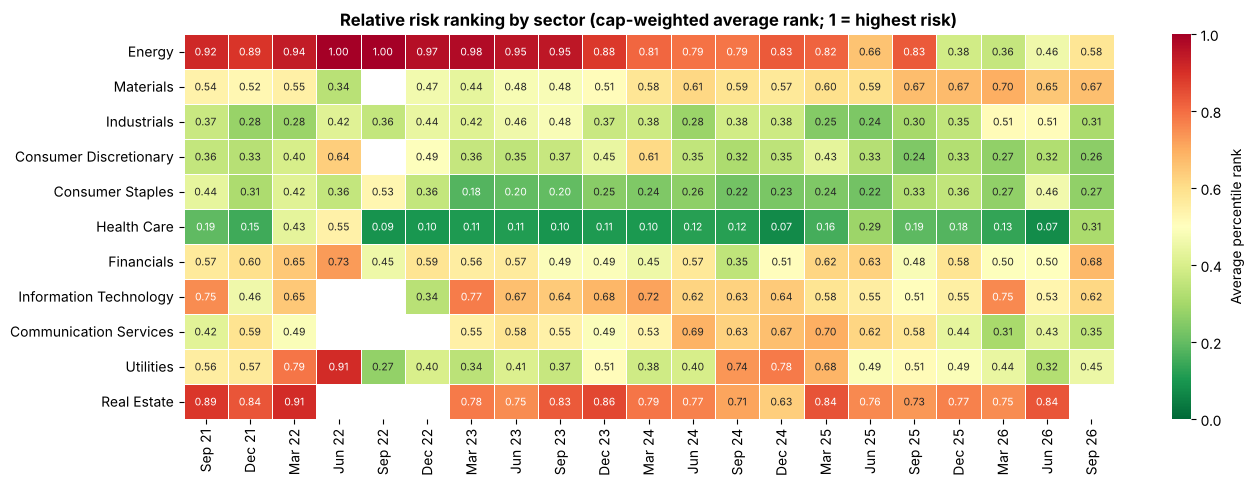

In [45]:
H5 = LV[LV["Rank"].notna()].loc[pd.IndexSlice[LAST - pd.DateOffset(years=5):, :], :].copy()
H5["Sector"] = H5.index.get_level_values("Industry").map(SECTOR_OF)
H5["wr"] = H5["MCap"] * H5["Rank"]
grp = H5.groupby([pd.Grouper(level="Date"), "Sector"])
heat = (grp["wr"].sum() / grp["MCap"].sum()).unstack("Sector").T.reindex(list(GICS_MAP))
heat = heat.loc[:, heat.columns[::-1][::3][::-1]]                    # every third month, ending at the latest
fig, ax = plt.subplots(figsize=(15, 5))
sns.heatmap(heat, cmap="RdYlGn_r", center=0.5, vmin=0, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7.5}, linewidths=0.4,
            xticklabels=[f"{d:%b %y}" for d in heat.columns], cbar_kws={"label": "Average percentile rank"}, ax=ax)
ax.set(xlabel="", ylabel="")
ax.set_title("Relative risk ranking by sector (cap-weighted average rank; 1 = highest risk)", fontsize=12, fontweight="bold")
save(fig, "report_sector_heatmap")

# Part 11 — Research findings that are not product functions

Everything in this part was tested and is reported so that a user can see the limits of the tool. None of it is offered as a function.

## 11.1 Timing: can the level of risk be forecast?
* **Purpose:** Test whether market-wide information can say *when* severe drawdowns will be frequent.
* **Method:** A two-stage model. Stage 1 is a Ridge regression of the share of industries that go on to a severe drawdown on market-wide variables only (GSADF share, CAPE percentile, credit spread, term spread, return dispersion, HMM probability), refitted yearly with the same embargo. Stage 2 is the ranking of Part 5; each month its scores are rescaled so that their average equals the Stage 1 level. The second table regresses the market's excess return over the next 24 months on market-level risk measures (in-sample, Newey–West with 24 lags); a useful warning needs a negative coefficient and agreement between the measures.
* **Reading:** a Time-AUC near 0.5, a Stage 1 R² at or below 0, and coefficients of mixed sign all mean there is no evidence of timing skill.

In [46]:
base_rate_m = PRED[MAIN_H]["Base rate"].groupby(level="Date").first()
def asof(s, lag, ffill):
    # value of month M becomes usable `lag` months later and is carried forward at most `ffill` months
    s = s.dropna()
    return s.reindex(pd.date_range(s.index[0], END, freq="ME")).shift(lag).ffill(limit=ffill).reindex(ret.index)

market = pd.DataFrame({
    "GSADF_Share":   ind_psy.mean(axis=1),
    "CAPE_Pctl":     asof(cape.expanding(min_periods=120).apply(lambda s: (s <= s[-1]).mean(), raw=True), CAPE_LAG, CAPE_FFILL),
    "Credit_Spread": asof(fred["BAA"] - fred["AAA"], FRED_LAG, FRED_FFILL),
    "Term_Spread":   asof(fred["GS10"] - fred["TB3MS"], FRED_LAG, FRED_FFILL),
    "Dispersion":    lag_return(ret, 12).std(axis=1),
    "HMM_HighVol":   regime_m["High volatility"].reindex(ret.index)})
MKT_FEATS = list(market.columns)
lab_rows = panel[~panel["Masked"]]
market["Crash share"] = lab_rows[f"Crash_{MAIN_H}"].groupby(level="Date").mean()   # realised share, known only at t + H

stage1 = pd.Series(np.nan, index=market.index, name="Stage 1 level")
for year in range(STAGE1_TEST_YEAR, market.index[-1].year + 1):
    fit_date = pd.Timestamp(f"{year - 1}-12-31")
    train = market.loc[:fit_date - pd.DateOffset(months=MAIN_H)].dropna()          # embargo
    test = market.loc[f"{year}", MKT_FEATS].dropna()
    w = 0.5 ** ((fit_date - train.index).days / 365.25 / HALF_LIFE)        # same half-life as Layer 3
    reg = Pipeline([("scale", StandardScaler()), ("reg", Ridge(alpha=1.0))])
    reg.fit(train[MKT_FEATS], train["Crash share"], reg__sample_weight=np.asarray(w))
    stage1.loc[test.index] = np.clip(reg.predict(test), 0.001, 0.999)

TS = PRED[MAIN_H].copy()
dates = TS.index.get_level_values("Date")
level = stage1.reindex(dates).values
mean_p = TS[MAIN_MODEL].where(~TS["Masked"]).groupby(level="Date").transform("mean").values
TS["Two-stage"] = np.clip(TS[MAIN_MODEL] * level / mean_p, 0, 1)
ew_ts = early_warning(TS[dates.year >= STAGE1_TEST_YEAR])
two_stage = evaluate(ew_ts, ["Base rate", MAIN_MODEL, "Two-stage"])
ts_diff = pd.Series(paired_diff(ew_ts, "Two-stage", MAIN_MODEL), name=f"Two-stage − {MAIN_MODEL}")

s1 = pd.concat([stage1, market["Crash share"], base_rate_m], axis=1).dropna()
stage1_skill = pd.Series({"Months": len(s1), "Correlation with realised crash share": s1["Stage 1 level"].corr(s1["Crash share"]),
                          "Out-of-sample R² vs base rate": 1 - ((s1["Stage 1 level"] - s1["Crash share"]) ** 2).sum()
                                                               / ((s1["Base rate"] - s1["Crash share"]) ** 2).sum()},
                         name="Stage 1").to_frame()
display(two_stage[["N", "Crash rate", "XS-AUC", "Time-AUC", "AUC", "AUC lo", "AUC hi", "BSS", "BSS lo", "BSS hi"]].round(3),
        ts_diff.to_frame().T[["ΔTime-AUC", "ΔTime-AUC lo", "ΔTime-AUC hi", "ΔAUC", "ΔAUC lo", "ΔAUC hi", "ΔBSS", "ΔBSS lo", "ΔBSS hi"]].round(3),
        stage1_skill.round(3))

,N,Crash rate,XS-AUC,Time-AUC,AUC,AUC lo,AUC hi,BSS,BSS lo,BSS hi
Base rate,22834,0.135,NaN,0.476,0.476,0.380,0.535,0.000,0.000,0.000
RandomForest,22834,0.135,0.702,0.501,0.617,0.545,0.706,0.036,0.020,0.065
Two-stage,22834,0.135,0.702,0.485,0.581,0.483,0.681,0.021,-0.016,0.059


,ΔTime-AUC,ΔTime-AUC lo,ΔTime-AUC hi,ΔAUC,ΔAUC lo,ΔAUC hi,ΔBSS,ΔBSS lo,ΔBSS hi
Two-stage − RandomForest,-0.016,-0.087,0.052,-0.036,-0.092,-0.001,-0.016,-0.051,0.006


,Stage 1
Months,596.000
Correlation with realised crash share,-0.079
Out-of-sample R² vs base rate,-0.121


In [47]:
alive = ~PRED[MAIN_H]["Masked"]
w_alive = PRED[MAIN_H]["MCap"].where(alive, 0.0)
MEASURES = {"Equal-weighted mean score": PRED[MAIN_H][MAIN_MODEL].where(alive).groupby(level="Date").mean(),
            "Cap-weighted mean score": (w_alive * PRED[MAIN_H][MAIN_MODEL]).groupby(level="Date").sum() / w_alive.groupby(level="Date").sum(),
            "GSADF share of industries": ind_psy.mean(axis=1).reindex(base_rate_m.index),
            "Stage 1 level": stage1}
excess = np.log1p(mkt) - np.log1p(RF_M.reindex(mkt.index))
fwd = excess.rolling(MAIN_H, min_periods=MAIN_H).sum().shift(-MAIN_H)             # months t+1 ... t+24
rows = []
for name, x in MEASURES.items():
    d = pd.concat([fwd.rename("y"), ((x - x.mean()) / x.std()).rename("x")], axis=1).dropna()
    fit = sm.OLS(d["y"], sm.add_constant(d["x"])).fit(cov_type="HAC", cov_kwds={"maxlags": MAIN_H})
    rows.append({"Predictor (1 sd)": name, "Months": len(d), "Coefficient": fit.params["x"], "t (Newey-West)": fit.tvalues["x"],
                 "p-value": fit.pvalues["x"], "R²": fit.rsquared})
market_reg = pd.DataFrame(rows).set_index("Predictor (1 sd)")
market_reg.round(3)

,Months,Coefficient,t (Newey-West),p-value,R²
Predictor (1 sd),,,,,
Equal-weighted mean score,776,0.056,2.218,0.027,0.065
Cap-weighted mean score,776,0.045,1.365,0.172,0.042
GSADF share of industries,777,-0.012,-0.482,0.630,0.003
Stage 1 level,597,-0.045,-1.944,0.052,0.048


## 11.2 Do the market-context variables improve the ranking?
* **Purpose:** Test whether the GSADF signals, the HMM regime or own-history features add ranking skill, which would justify treating them as signals.
* **Method:** Each variant is compared with the main feature set on identical rows at 24 months. P-values are adjusted with the Benjamini–Hochberg false discovery rate. A result of "none" means the variable is shown as context only.

In [48]:
ew_abl = early_warning(ABL)
rows = []
for fam in ["Logit", "RF"]:
    for name in list(ABL_SETS)[1:]:
        d = paired_diff(ew_abl, f"{fam} | {name}", f"{fam} | Main")
        rows.append({"Model": fam, "Variant vs Main": name, **d})
abl_tests = pd.DataFrame(rows).set_index(["Model", "Variant vs Main"])
p_cols = ["p XS-AUC", "p Time-AUC", "p AUC", "p BSS"]
p_adj = multipletests(abl_tests[p_cols].values.ravel(), alpha=0.10, method="fdr_bh")[1].reshape(abl_tests[p_cols].shape)
abl_tests["Significant (FDR 10%)"] = [", ".join(c[2:] for c, q in zip(p_cols, row) if q < 0.10) or "none" for row in p_adj]
abl_scores = evaluate(ew_abl, list(ABL_SPECS))[["N", "XS-AUC", "Time-AUC", "AUC", "BSS"]]
display(abl_scores.round(3),
        abl_tests[["ΔXS-AUC", "ΔXS-AUC lo", "ΔXS-AUC hi", "ΔTime-AUC", "ΔTime-AUC lo", "ΔTime-AUC hi",
                   "ΔAUC", "ΔAUC lo", "ΔAUC hi", "ΔBSS", "ΔBSS lo", "ΔBSS hi", "Significant (FDR 10%)"]].round(3))

,N,XS-AUC,Time-AUC,AUC,BSS
Logit | Main,28139,0.678,0.524,0.618,0.032
Logit | Main + bubble signals,28139,0.680,0.531,0.620,0.030
Logit | Main + HMM regime,28139,0.678,0.510,0.611,0.029
Logit | Main + own history,28139,0.668,0.508,0.613,0.003
Logit | Main + all,28139,0.668,0.501,0.607,-0.001
RF | Main,28139,0.701,0.511,0.621,0.035
RF | Main + bubble signals,28139,0.703,0.511,0.625,0.037
RF | Main + HMM regime,28139,0.701,0.502,0.617,0.035
RF | Main + own history,28139,0.695,0.503,0.618,0.035
RF | Main + all,28139,0.697,0.499,0.618,0.034


ΔXS-AUC  ΔXS-AUC lo  ΔXS-AUC hi  ΔTime-AUC  ΔTime-AUC lo  ΔTime-AUC hi   ΔAUC  ΔAUC lo  ΔAUC hi   ΔBSS  ΔBSS lo  ΔBSS hi Significant (FDR 10%)
Model Variant vs Main                                                                                                                                                      
Logit Main + bubble signals    0.002      -0.009       0.013      0.007        -0.001         0.020  0.002   -0.007    0.009 -0.002   -0.008    0.003                  none
      Main + HMM regime       -0.000      -0.004       0.003     -0.014        -0.041         0.011 -0.007   -0.016    0.001 -0.003   -0.012    0.003                  none
      Main + own history      -0.010      -0.022       0.000     -0.016        -0.072         0.035 -0.005   -0.026    0.017 -0.028   -0.084    0.001                  none
      Main + all              -0.010      -0.020       0.002     -0.023        -0.077         0.028 -0.011   -0.032    0.012 -0.033   -0.095   -0.001                  none
RF    Main + bubble signals    0.002      -0.007       0.011      0.001        -0.004         0.005  0.004   -0.004    0.012  0.002   -0.001    0.005                  none
      Main + HMM regime       -0.000      -0.006       0.005     -0.008        -0.032         0.015 -0.004   -0.012    0.005 -0.000   -0.005    0.003                  none
      Main + own history      -0.006      -0.018       0.003     -0.008        -0.036         0.022 -0.003   -0.012    0.007 -0.000   -0.003    0.003                  none
      Main + all              -0.004      -0.017       0.006     -0.012        -0.044         0.023 -0.003   -0.014    0.008 -0.001   -0.005    0.003                  none

## 11.3 Acting mechanically on the signal: long–short test
* **Purpose:** Measure whether the ranking predicts **returns**, not only severe drawdowns.
* **Method:** A portfolio engine sets weights at the end of month *t* and earns the return of month *t+1*, net of 10 bps of traded value. Each month it holds the equal-weighted quintile ranked lowest and shorts the quintile ranked highest. Alpha comes from CAPM and Fama–French three-factor regressions (Newey–West, 12 lags). The short leg is a measuring device only. A negative alpha means the industries ranked risky earned more, not less.

In [49]:
def run_portfolio(w, cost_bps=COST_BPS):
    r_next  = ret.shift(-1).reindex(index=w.index, columns=w.columns)              # return of month t+1
    rf_next = RF_M.shift(-1).reindex(w.index)
    keep = r_next.notna().any(axis=1) & rf_next.notna()
    Wt, R, F = w[keep].fillna(0.0).values, r_next[keep].fillna(0.0).values, rf_next[keep].values
    assert (Wt >= -1e-12).all() and (Wt.sum(axis=1) <= 1 + 1e-9).all(), "weights must be long-only and sum to at most 1"
    gross, turn, prev = np.zeros(len(Wt)), np.zeros(len(Wt)), np.zeros(Wt.shape[1])
    for t in range(len(Wt)):
        turn[t]  = np.abs(Wt[t] - prev).sum()                                      # trade at the end of month t
        gross[t] = Wt[t] @ R[t] + (1 - Wt[t].sum()) * F[t]
        prev = Wt[t] * (1 + R[t]) / (1 + gross[t])                                 # weights after drifting through t+1
    idx = w.index[keep] + pd.offsets.MonthEnd(1)                                   # month in which the return is earned
    return pd.DataFrame({"gross": gross, "cost": cost_bps / 1e4 * turn, "net": gross - cost_bps / 1e4 * turn,
                         "turnover": turn, "cash": 1 - Wt.sum(axis=1)}, index=idx)

def perf(r):
    r = r.dropna()
    rf, m_ex = RF_M.reindex(r.index), (mkt - RF_M.reindex(mkt.index)).reindex(r.index)
    cum = (1 + r).cumprod()
    cagr, vol = cum.iloc[-1] ** (12 / len(r)) - 1, r.std() * np.sqrt(12)
    mdd = (cum / cum.cummax().clip(lower=1.0) - 1).min()
    down = m_ex < 0
    return {"Ann. return": r.mean() * 12, "CAGR": cagr, "Ann. vol": vol, "Sharpe": (r - rf).mean() * 12 / vol,
            "Max drawdown": mdd, "Calmar": cagr / abs(mdd), "CVaR 5% (monthly)": -r[r <= r.quantile(0.05)].mean(),
            "Downside beta": np.cov((r - rf)[down], m_ex[down])[0, 1] / m_ex[down].var()}

def diff_ci(r, ctrl):
    d = (r - ctrl).dropna().values
    lo, hi = np.percentile([d[ix].mean() * 12 for ix in block_positions(len(d))], [2.5, 97.5])
    return {"Δ ann. return vs control": d.mean() * 12, "Δ lo": lo, "Δ hi": hi}

P_wide    = PRED[MAIN_H][MODELS].where(~PRED[MAIN_H]["Masked"]).unstack("Industry")   # P of industries not already falling
cap_wide  = PRED[MAIN_H]["MCap"].unstack("Industry")
BASE_W = {"Cap-weighted": cap_wide.div(cap_wide.sum(axis=1), axis=0),
          "Equal-weighted": cap_wide.notna().div(cap_wide.notna().sum(axis=1), axis=0)}

def quintile_ls(model):
    q = P_wide[model].rank(axis=1, pct=True)
    legs = [run_portfolio(sel.div(sel.sum(axis=1), axis=0).astype(float)) for sel in (q <= 0.2, q >= 0.8)]
    return (legs[0]["gross"] - legs[1]["gross"] - legs[0]["cost"] - legs[1]["cost"]).rename(model)

rows = {}
for m in MODELS:
    ls = quintile_ls(m)
    X = ff[["Mkt-RF", "SMB", "HML"]].reindex(ls.index)
    capm = sm.OLS(ls, sm.add_constant(X[["Mkt-RF"]]), missing="drop").fit(cov_type="HAC", cov_kwds={"maxlags": 12})
    ff3  = sm.OLS(ls, sm.add_constant(X), missing="drop").fit(cov_type="HAC", cov_kwds={"maxlags": 12})
    rows[m] = {"Months": len(ls), "Ann. return (x12)": ls.mean() * 12, "Ann. vol (x sqrt12)": ls.std() * np.sqrt(12),
               "CAPM alpha (ann.)": capm.params["const"] * 12, "t CAPM": capm.tvalues["const"], "Market beta": capm.params["Mkt-RF"],
               "FF3 alpha (ann.)": ff3.params["const"] * 12, "t FF3": ff3.tvalues["const"]}
ls_table = pd.DataFrame(rows).T.astype({"Months": int})
ls_table.round(3)

,Months,Ann. return (x12),Ann. vol (x sqrt12),CAPM alpha (ann.),t CAPM,Market beta,FF3 alpha (ann.),t FF3
Logit-Vol,800,-0.028,0.135,0.004,0.200,-0.432,-0.002,-0.107
Logit,800,-0.052,0.137,-0.021,-1.189,-0.419,-0.024,-1.326
RandomForest,800,-0.041,0.118,-0.025,-1.481,-0.230,-0.026,-1.547


## 11.4 Reducing weight in High-level industries: the trade-off
* **Purpose:** Show a user what reducing exposure to flagged industries would have done, so the trade-off is visible. It is a finding, not a recommended rule.
* **Method:** Cap-weighted and equal-weighted portfolios with three adjustments: High-level industries halved, removed with the weight spread over the other industries, or removed with the weight placed in T-bills. `Severe-drawdown exposure` is the share of portfolio weight held in industries that went on to a relative drawdown of at least 30% within 24 months. The exposure-matched control holds the unadjusted portfolio with the same average T-bill share, so a lower drawdown cannot come from simply holding less equity.

In [50]:
high_w = lv.eq("High").reindex(index=cap_wide.index, columns=cap_wide.columns).fillna(False)
rescale = lambda w: w.div(w.sum(axis=1), axis=0)

def exposure(w):
    """Share of the equity weight held in industries that go on to a severe drawdown (months with a known outcome)."""
    known = Yw.reindex(index=w.index, columns=w.columns)
    ok = known.notna().any(axis=1)
    return ((w * known).sum(axis=1) / w.where(known.notna()).sum(axis=1))[ok]

bt_rows, BT = [], {}
for scheme, base in BASE_W.items():
    plans = {"Control": base,
             "High level halved": rescale(base.where(~high_w, base * 0.5)),
             "High level removed, weight to other industries": rescale(base.where(~high_w, 0.0)),
             "High level removed, weight to T-bills": base.where(~high_w, 0.0)}
    plans["Exposure-matched control"] = base * plans["High level removed, weight to T-bills"].sum(axis=1).mean()
    for name, w in plans.items():
        BT[(scheme, name)] = (w, run_portfolio(w))
bt_common = sorted(set.intersection(*[set(r.index) for _, r in BT.values()]))
for (scheme, name), (w, r) in BT.items():
    w0, r0 = BT[(scheme, "Control")]
    net, ctrl = r["net"].reindex(bt_common), r0["net"].reindex(bt_common)
    e, e0 = exposure(rescale(w)), exposure(w0)
    d = (e - e0).values
    row = {"Weighting": scheme, "Adjustment": name, "Severe-drawdown exposure": e.mean(), **{k: perf(net)[k] for k in ["CAGR", "Ann. vol", "Sharpe", "Max drawdown", "CVaR 5% (monthly)"]},
           "Avg. T-bill share": r["cash"].reindex(bt_common).mean(), "Turnover (one-way, /yr)": r["turnover"].reindex(bt_common).mean() * 6}
    if name != "Control":
        lo, hi = np.percentile([d[ix].mean() for ix in block_positions(len(d))], [2.5, 97.5])
        row.update({"Δ exposure": d.mean(), "Δ exp. lo": lo, "Δ exp. hi": hi, **diff_ci(net, ctrl)})
    bt_rows.append(row)
BT_TABLE = pd.DataFrame(bt_rows).set_index(["Weighting", "Adjustment"])
print(f"Common sample: {bt_common[0]:%Y-%m} to {bt_common[-1]:%Y-%m} ({len(bt_common)} months), net of {COST_BPS} bps per unit traded")
BT_TABLE.round(3)

Common sample: 1960-02 to 2026-09 (800 months), net of 10 bps per unit traded


Severe-drawdown exposure   CAGR  Ann. vol  Sharpe  Max drawdown  CVaR 5% (monthly)  Avg. T-bill share  Turnover (one-way, /yr)  Δ exposure  Δ exp. lo  Δ exp. hi  \
Weighting      Adjustment                                                                                                                                                                                                         
Cap-weighted   Control                                                            0.099  0.108     0.153   0.472        -0.500              0.096              0.000                    0.255         NaN        NaN        NaN   
               High level halved                                                  0.093  0.105     0.152   0.457        -0.504              0.096              0.000                    0.540      -0.006     -0.011     -0.003   
               High level removed, weight to other industries                     0.084  0.100     0.150   0.426        -0.512              0.096              0.000                    0.999      -0.015     -0.027     -0.006   
               High level removed, weight to T-bills                              0.084  0.090     0.125   0.412        -0.457              0.080              0.189                    0.667      -0.015     -0.027     -0.006   
               Exposure-matched control                                           0.099  0.098     0.124   0.472        -0.424              0.077              0.189                    0.209       0.000     -0.000      0.000   
Equal-weighted Control                                                            0.138  0.112     0.168   0.467        -0.526              0.106             -0.000                    0.216         NaN        NaN        NaN   
               High level halved                                                  0.128  0.108     0.166   0.449        -0.532              0.105              0.000                    0.516      -0.010     -0.014     -0.008   
               High level removed, weight to other industries                     0.114  0.103     0.165   0.424        -0.543              0.105              0.000                    0.939      -0.024     -0.032     -0.018   
               High level removed, weight to T-bills                              0.114  0.093     0.134   0.415        -0.494              0.085              0.229                    0.698      -0.024     -0.032     -0.018   
               Exposure-matched control                                           0.138  0.099     0.129   0.467        -0.428              0.081              0.229                    0.171      -0.000     -0.000      0.000   

                                                               Δ ann. return vs control   Δ lo   Δ hi  
Weighting      Adjustment                                                                              
Cap-weighted   Control                                                              NaN    NaN    NaN  
               High level halved                                                 -0.003 -0.006 -0.001  
               High level removed, weight to other industries                    -0.008 -0.015 -0.002  
               High level removed, weight to T-bills                             -0.021 -0.032 -0.010  
               Exposure-matched control                                          -0.014 -0.020 -0.006  
Equal-weighted Control                                                              NaN    NaN    NaN  
               High level halved                                                 -0.004 -0.006 -0.002  
               High level removed, weight to other industries                    -0.009 -0.014 -0.005  
               High level removed, weight to T-bills                             -0.023 -0.033 -0.015  
               Exposure-matched control                                          -0.018 -0.026 -0.009

## 11.5 Why there is no portfolio risk score
* **Purpose:** Test whether a weighted average of the industry rankings says anything about the portfolio's own outcome.
* **Method:** Thirty random equal-weighted portfolios of 10 industries are drawn each month. The score is the average percentile rank of the holdings; the benchmark score is their average volatility rank. The outcome is the portfolio's own maximum drawdown over the next 24 months (relative to the market, and absolute), so the co-movement of the holdings is inside the outcome. The table gives the average within-month rank correlation between score and outcome. A score that is weaker than the volatility benchmark does not earn a place in the product.

In [51]:
vol_rank = panel["Vol6_R"].unstack("Industry").reindex(rk.index)
rng, recs = np.random.default_rng(SEED), []
for d in rk.index[rk.index <= ret.index[-MAIN_H - 1]]:
    fut, mk = ret.loc[d:].iloc[1:MAIN_H + 1], mkt.loc[d:].iloc[1:MAIN_H + 1].values
    avail = [i for i in rk.loc[d].dropna().index if fut[i].notna().all()]
    if len(avail) < 20:
        continue
    for _ in range(30):
        pick = rng.choice(avail, 10, replace=False)
        pr = fut[pick].mean(axis=1).values                                         # equal weight, rebalanced monthly
        rel_path = np.concatenate([[1.0], np.cumprod((1 + pr) / (1 + mk))])
        abs_path = np.concatenate([[1.0], np.cumprod(1 + pr)])
        recs.append((d, rk.loc[d, pick].mean(), vol_rank.loc[d, pick].mean(),
                     (1 - rel_path / np.maximum.accumulate(rel_path)).max(), (1 - abs_path / np.maximum.accumulate(abs_path)).max()))
SIM = pd.DataFrame(recs, columns=["Date", "Ranking score", "Volatility score", "Relative max drawdown", "Absolute max drawdown"])
ic = lambda a, b: SIM.groupby("Date").apply(lambda g: stats.spearmanr(g[a], g[b])[0])
score_test = pd.DataFrame({(out, stat_): val for out in ["Relative max drawdown", "Absolute max drawdown"]
                           for stat_, val in {"Mean rank correlation": {s: ic(s, out).mean() for s in ["Ranking score", "Volatility score"]},
                                              "Months with a positive correlation": {s: (ic(s, out) > 0).mean() for s in ["Ranking score", "Volatility score"]}}.items()})
SIM["Score quintile"] = SIM.groupby("Date")["Ranking score"].transform(lambda s: pd.qcut(s.rank(method="first"), 5, labels=False)) + 1
display(score_test.round(3), SIM.groupby("Score quintile")[["Ranking score", "Relative max drawdown", "Absolute max drawdown"]].mean().round(3))

Relative max drawdown                                    Absolute max drawdown                                   
                 Mean rank correlation Months with a positive correlation Mean rank correlation Months with a positive correlation
Ranking score                    0.126                              0.679                 0.175                              0.719
Volatility score                 0.169                              0.724                 0.276                              0.846

,Ranking score,Relative max drawdown,Absolute max drawdown
Score quintile,,,
1,0.406,0.073,0.166
2,0.471,0.075,0.170
3,0.513,0.077,0.173
4,0.555,0.078,0.175
5,0.620,0.084,0.181


## 11.6 Robustness to other settings
* **Purpose:** Check that the ranking result does not depend on one setting.
* **Method:** One setting is changed at a time and the 24-month walk-forward is rerun: relative threshold 20% or 40%, the absolute target, features with no cross-sectional ranks at all (winsorised), and the half-lives that were not chosen in 5.3.

In [52]:
for dd in (0.20, 0.40):
    lab = crash_label(rel_px, MAIN_H, dd).stack().rename(f"Crash_{MAIN_H}_dd{int(dd * 100)}")
    panel[lab.name] = lab.reindex(panel.index)
SPECS_2  = {m: MODEL_SPECS[m] for m in [BENCH_MODEL, MAIN_MODEL]}
RAW_SPEC = {BENCH_MODEL: ("logit", FEATS_RAW), MAIN_MODEL: ("rf", FEATS_RAW)}
main_lab = f"Crash_{MAIN_H}"
hl_name = lambda hl: "No time decay" if np.isinf(hl) else f"Half-life {hl:g} years"
SCENARIOS = {f"Baseline (relative {REL_DD:.0%}, {hl_name(HALF_LIFE).lower()})": PRED[MAIN_H],
             "Relative threshold 20%":          walk_forward(f"{main_lab}_dd20", SPECS_2, MAIN_H)[0],
             "Relative threshold 40%":          walk_forward(f"{main_lab}_dd40", SPECS_2, MAIN_H)[0],
             f"Absolute label ({ABS_DD:.0%})":  PRED_ABS,
             "Raw features (no ranks)":         walk_forward(main_lab, RAW_SPEC, MAIN_H, rows=panel.dropna(subset=FEATS_RAW))[0],
             **{hl_name(hl): walk_forward(main_lab, SPECS_2, MAIN_H, half_life=hl)[0] for hl in HALF_LIFE_GRID if hl != HALF_LIFE}}
rows = []
for name, pred in SCENARIOS.items():
    res = evaluate(early_warning(pred), list(SPECS_2))
    for m in SPECS_2:
        rows.append({"Scenario": name, "Model": m, **res.loc[m, ["N", "Crash rate", "XS-AUC", "Time-AUC", "AUC", "BSS", "BSS lo", "BSS hi"]].to_dict()})
robust = pd.DataFrame(rows).set_index(["Scenario", "Model"]).astype({"N": int})
robust.round(3)

N  Crash rate  XS-AUC  Time-AUC    AUC    BSS  BSS lo  BSS hi
Scenario                               Model                                                                          
Baseline (relative 30%, no time decay) Logit         28503       0.131   0.677     0.527  0.623  0.036   0.016   0.063
                                       RandomForest  28503       0.131   0.712     0.514  0.631  0.036   0.023   0.058
Relative threshold 20%                 Logit         28503       0.331   0.624     0.505  0.608  0.046   0.026   0.076
                                       RandomForest  28503       0.331   0.636     0.502  0.610  0.042   0.025   0.063
Relative threshold 40%                 Logit         28503       0.050   0.729     0.569  0.626  0.039   0.014   0.079
                                       RandomForest  28503       0.050   0.764     0.518  0.652  0.033   0.018   0.056
Absolute label (40%)                   Logit         28503       0.089   0.737     0.459  0.594  0.035   0.003   0.068
                                       RandomForest  28503       0.089   0.740     0.315  0.550  0.021   0.007   0.037
Raw features (no ranks)                Logit         28503       0.131   0.700     0.513  0.589  0.020  -0.014   0.052
                                       RandomForest  28503       0.131   0.679     0.535  0.608  0.027   0.003   0.047
Half-life 10 years                     Logit         28503       0.131   0.669     0.483  0.597  0.026   0.008   0.054
                                       RandomForest  28503       0.131   0.701     0.472  0.591  0.028   0.016   0.047
Half-life 20 years                     Logit         28503       0.131   0.676     0.506  0.611  0.032   0.013   0.061
                                       RandomForest  28503       0.131   0.710     0.494  0.612  0.033   0.020   0.054
Half-life 40 years                     Logit         28503       0.131   0.678     0.517  0.618  0.035   0.015   0.063
                                       RandomForest  28503       0.131   0.711     0.509  0.622  0.035   0.022   0.057

## 11.7 Overfitting: in-sample versus out-of-sample
* **Purpose:** Measure how much of the fit does not carry over to new data.
* **Method:** Both scores are AUCs inside a single calendar year, so they measure the same thing. In-sample: the average over the years of the training set. Out-of-sample: the following test year. Both are averaged over the fits whose test year contains both outcomes.

In [53]:
rows = []
for H in H_LIST:
    ew_y = EW[H].assign(Year=EW[H].index.get_level_values("Date").year)
    for m in MODELS:
        oos = pd.Series({yr: roc_auc_score(g["y"], g[m]) for yr, g in ew_y.groupby("Year") if g["y"].nunique() == 2})
        ins = INSAMPLE[H].query("Model == @m").set_index("Year")["AUC in-sample"].reindex(oos.index)
        rows.append({"Horizon (months)": H, "Model": m, "Fits": len(oos), "AUC in-sample": ins.mean(),
                     "AUC next year": oos.mean(), "Gap": ins.mean() - oos.mean()})
overfit = pd.DataFrame(rows).set_index(["Horizon (months)", "Model"])
overfit.round(3)

Fits  AUC in-sample  AUC next year    Gap
Horizon (months) Model                                                  
6                Logit-Vol       33          0.882          0.867  0.015
                 Logit           33          0.890          0.834  0.056
                 RandomForest    33          0.949          0.859  0.090
12               Logit-Vol       57          0.736          0.798 -0.062
                 Logit           57          0.775          0.765  0.010
                 RandomForest    57          0.857          0.784  0.072
24               Logit-Vol       65          0.666          0.700 -0.033
                 Logit           65          0.675          0.668  0.007
                 RandomForest    65          0.730          0.702  0.028

# Part 12 — Summary

## 12.1 Headline numbers
* **Purpose:** Collect the results that the product claims rest on in one table.
* **Method:** All values are taken from the tables above; nothing is recomputed.

In [54]:
r_main, r_vol = results[MAIN_H].loc[MAIN_MODEL], results[MAIN_H].loc[VOL_MODEL]
ci = lambda r, k: f"{r[k]:.3f} [{r[k + ' lo']:.3f}, {r[k + ' hi']:.3f}]"
pct_ci = lambda v, lo, hi: f"{v:.1%} [{lo:.1%}, {hi:.1%}]"
vt = vol_test.loc[(vol_test.index[0][0], MAIN_MODEL)]
ru, ru_hi = runup_table.loc[f">= {RUNUP_2Y:.0%}"], runup_table.iloc[-1]
oos = runup_periods.iloc[-1]
cw = BT_TABLE.loc["Cap-weighted"]
adj = cw.loc["High level removed, weight to other industries"]
summary = pd.Series({
    "Risk Ranking sample":                                   f"{t_dates.min():%Y-%m} to {t_dates.max():%Y-%m}, {len(T):,} rated industry-months with a known outcome",
    "Risk Ranking: severe-drawdown rate, Low level":         pct_ci(*level_table.loc["Low", ["Rate 24M", "95% lo", "95% hi"]]),
    "Risk Ranking: severe-drawdown rate, High level":        pct_ci(*level_table.loc["High", ["Rate 24M", "95% lo", "95% hi"]]),
    "Risk Ranking: rates rise Low to High":                  f"{level_facts.iloc[2, 0]} of bootstrap draws; {int(period_table['Rates rise Low to High'].sum())} of {len(period_table)} periods",
    f"Ranking skill, XS-AUC ({MAIN_MODEL})":                 ci(r_main, "XS-AUC"),
    f"Ranking skill, XS-AUC (volatility-only benchmark)":    ci(r_vol, "XS-AUC"),
    f"ΔXS-AUC, {MAIN_MODEL} − volatility-only":              f"{vt['ΔXS-AUC vs Logit-Vol']:+.3f} [{vt['Δ lo']:+.3f}, {vt['Δ hi']:+.3f}]",
    "Does ML add value over the volatility benchmark?":      ("not shown: the interval of the difference includes 0" if vt["Δ lo"] <= 0 <= vt["Δ hi"]
                                                              else "yes: the interval is above 0" if vt["Δ lo"] > 0 else "no: the interval is below 0"),
    "High level: model − volatility ranking (rate)":         "{:+.1%} [{:+.1%}, {:+.1%}]".format(*level_vs_vol.loc["High level — difference"]),
    "High level vs control matched on return and volatility": "{:.1%} vs {:.1%} (diff {:+.1%} [{:+.1%}, {:+.1%}])".format(*control_table.iloc[0][["Rate when flagged", "Matched control", "Difference", "Diff lo", "Diff hi"]]),
    "Level stability: same level next month":                f"{stability.loc['Same level next month', 'Value']:.1%}",
    "High signal, rule A vs B: events flagged in advance":   f"{rule_table.iloc[0]['Events flagged in advance']:.1%} vs {rule_table.iloc[1]['Events flagged in advance']:.1%}",
    "High signal, rule A vs B: false-alarm rate":            f"{rule_table.iloc[0]['False-alarm rate']:.1%} vs {rule_table.iloc[1]['False-alarm rate']:.1%}",
    f"Run-up Watch (>= {RUNUP_2Y:.0%}): episodes / severe drawdowns": f"{int(ru['Episodes'])} / {int(ru['Severe drawdowns'])}",
    f"Run-up Watch (>= {RUNUP_2Y:.0%}): rate per episode":   pct_ci(ru["Rate"], ru["Year-cluster lo"], ru["Year-cluster hi"]),
    f"Run-up Watch (>= {RUNUP_2Y:.0%}): matched control / difference": f"{ru['Matched control']:.1%} / {ru['Difference']:+.1%} [{ru['Diff lo']:+.1%}, {ru['Diff hi']:+.1%}]",
    f"Run-up Watch ({runup_table.index[-1]}): rate per episode": f"{pct_ci(ru_hi['Rate'], ru_hi['Year-cluster lo'], ru_hi['Year-cluster hi'])}, {int(ru_hi['Episodes'])} episodes",
    "Run-up Watch, out of sample (2015 onwards)":            f"{int(oos['Drawdowns'])} of {int(oos['Episodes'])} episodes [{oos['Wilson lo']:.1%}, {oos['Wilson hi']:.1%}]; matched control {oos['Matched control']:.1%}",
    "Run-up Watch: months from signal to price peak (mean)": f"{after.loc['All episodes', 'Months to peak (mean)']:.1f}, return to peak {after.loc['All episodes', 'Return to peak']:+.0%}",
    f"Timing skill, Time-AUC ({MAIN_MODEL})":                ci(r_main, "Time-AUC"),
    "Stage 1 out-of-sample R² vs base rate":                 f"{stage1_skill.loc['Out-of-sample R² vs base rate', 'Stage 1']:+.3f}",
    "Market-context variables that improve the ranking (FDR 10%)": ", ".join(sorted(set(abl_tests["Significant (FDR 10%)"]) - {"none"})) or "none",
    f"Long–short FF3 alpha per year ({MAIN_MODEL})":         f"{ls_table.loc[MAIN_MODEL, 'FF3 alpha (ann.)']:+.1%} (t = {ls_table.loc[MAIN_MODEL, 't FF3']:.2f})",
    "Removing High level (cap-weighted): exposure":          f"{cw.loc['Control', 'Severe-drawdown exposure']:.1%} to {adj['Severe-drawdown exposure']:.1%} (Δ {adj['Δ exposure']:+.1%} [{adj['Δ exp. lo']:+.1%}, {adj['Δ exp. hi']:+.1%}])",
    "Removing High level (cap-weighted): return per year":   f"{adj['Δ ann. return vs control']:+.2%} [{adj['Δ lo']:+.2%}, {adj['Δ hi']:+.2%}]",
    "Removing High level (cap-weighted): max drawdown vs control": f"{adj['Max drawdown']:.1%} vs {cw.loc['Control', 'Max drawdown']:.1%}",
    "Portfolio score vs volatility score (rank corr. with relative drawdown)": "{:+.3f} vs {:+.3f}".format(*score_test[("Relative max drawdown", "Mean rank correlation")]),
}, name="Value")
summary.to_frame()

,Value
Risk Ranking sample,"1960-01 to 2024-09, 28,503 rated industry-months with a known outcome"
"Risk Ranking: severe-drawdown rate, Low level","7.4% [3.2%, 11.1%]"
"Risk Ranking: severe-drawdown rate, High level","22.2% [17.8%, 26.2%]"
Risk Ranking: rates rise Low to High,99% of bootstrap draws; 3 of 3 periods
"Ranking skill, XS-AUC (RandomForest)","0.712 [0.683, 0.748]"
"Ranking skill, XS-AUC (volatility-only benchmark)","0.703 [0.666, 0.742]"
"ΔXS-AUC, RandomForest − volatility-only","+0.009 [-0.016, +0.043]"
Does ML add value over the volatility benchmark?,not shown: the interval of the difference includes 0
High level: model − volatility ranking (rate),"-1.0% [-2.5%, +0.7%]"
High level vs control matched on return and volatility,"22.2% vs 14.5% (diff +7.7% [+3.8%, +11.8%])"


## 12.2 What each function can and cannot claim
* **Purpose:** State the product claims and tie each one to its evidence.
* **Method:** Numbers are out-of-sample for 1960-01 to 2024-09 unless stated. "Severe drawdown" means the target of that function (4.2).

| Function | Supported by the evidence | Not claimed |
|---|---|---|
| **Industry Risk Ranking** | The four levels separate risk: 7.4% of Low-level industry-months were followed by a severe drawdown within 24 months against 22.2% of High-level ones; the rates rise at every step in 99% of bootstrap draws and in all three 20-year periods (6.3, 6.4). Levels are stable: 74.1% keep their level the next month (6.6). High-level industries had more severe drawdowns than industries with a similar past return and volatility, 22.2% against 14.5% (6.5). | That machine learning is more accurate than a traditional risk measure. The Random Forest was tested against a volatility-only ranking: XS-AUC 0.712 against 0.703, a difference of +0.009 whose interval (−0.016 to +0.043) includes zero, and the High level of the volatility ranking has a slightly higher rate (6.5). The value offered is a tested, monthly, industry-level relative ranking with its history attached. Levels are relative, not absolute. |
| **Run-up Watch** | A historical pattern: 19 of 46 run-up episodes (41%, interval 21–59%) were followed by a drawdown of at least 40% within 24 months. A matched control counted the same way, the other industries in the same months that were not in a run-up and not already falling, had a rate of 16%; the difference is 25 percentage points (year-clustered interval 9 to 39). The difference grows with the size of the run-up, in nested groups (7.1, 7.2). | That it is a validated early-warning signal. After the paper's sample only 1 of 7 episodes was followed by a severe drawdown, against 6% for its matched control (7.3); seven episodes are too few to confirm the pattern. Prices peaked about 12 months after the flag on average, 44% higher (7.4), and the ranking model cannot tell which run-ups end badly (7.5). |
| **Portfolio Exposure Review** | A description of where a portfolio's weight sits in the ranking, and which holdings are High or in a run-up (8.1). | Any portfolio score, probability of loss or risk contribution. A weighted score was weaker than a volatility score (11.5). |
| **Why This Industry Is Flagged** | The inputs that moved the model's score for each industry; volatility accounts for about 60% of the importance (9.1, 9.2). | Causes of a drawdown. |
| **Market Context** | A monthly description of the volatility regime and explosive price behaviour (Parts 2, 3), computed each month from data up to that month. | Any predictive value: these variables did not improve the ranking, and no timing skill was found (11.1, 11.2). |

**On machine learning versus a traditional benchmark (6.5).** The tool tests its machine-learning model against a traditional benchmark, a ranking by volatility alone. The results do not confirm that machine learning adds significant value: the difference in ranking skill is small and its interval includes zero. The product is therefore not presented as more accurate than traditional risk measures.

**On confirming a High signal (6.7).** Requiring two months in a row lowered the false-alarm rate only from 77.8% to 76.6% and reduced the share of events flagged in advance from 54.4% to 48.5%. The report therefore shows every High signal and labels it `Watch` (first month) or `Confirmed` (two or more months), and leaves the choice to the user.

**On acting on the signal (11.3, 11.4).** The historical portfolio analysis suggests that reducing exposure to flagged industries can modestly lower subsequent exposure to severe drawdowns (9.9% to 8.4% of a cap-weighted portfolio). However, this reduction comes with a return trade-off (about 0.8% a year) and does not demonstrate an improvement in maximum drawdown. Industries ranked High did not earn less: the low-minus-high portfolio has an alpha of −2.6% a year, which is not statistically significant (t = −1.5). The tool is therefore positioned as decision support for risk review, and it does not adjust weights.


## 12.3 Limitations
* **Scope of "risk":** the tool measures the risk of a severe price drawdown only. It does not cover liquidity, credit, valuation or concentration risk and is not a measure of total investment risk.
* **Relative levels:** a quarter of the rated industries is always High. The historical rate of a level changed between periods (High: 18% to 24%), so it is a guide to relative risk and not a forecast.
* **Uniform thresholds:** the same 30% and 40% thresholds are used for every industry, so volatile industries reach them more easily. This is one reason volatility dominates the ranking. A threshold scaled to each industry's volatility was not tested.
* **Run-up Watch:** 46 episodes in almost a century, nested threshold groups, and weak out-of-sample support. The 100% rule comes from the paper; no threshold was selected for its result here.
* **Choices made after earlier runs:** the Risk Ranking target was changed from the absolute to the relative definition, and the product functions were chosen after seeing which tests held. The results are not a pre-registered test.
* **Dependence:** industries fall together and 24-month windows overlap, so the effective sample is far smaller than the row count. Intervals use month-block or year-cluster resampling and depend on those choices.
* **Frequency:** data and report are monthly, and models are refitted once a year. The tool is not real-time monitoring and can lag a fast-moving market.
* **Universe and mapping:** 48 Fama–French industry portfolios (49 minus "Other"), which are not tradable funds. Client holdings must be mapped to these industries, and conglomerates may not map cleanly. One industry can exceed a fifth of total market value, which dominates any cap-weighted view.
* **Market context:** the GSADF test (lag 0) flags steadily rising defensive sectors more often than Information Technology, and the "High volatility" regime covers about 44% of all days. Both are descriptive.
* **Data:** revised historical data, not the vintages available at the time.

## 12.4 Business validation and future development
The research above does not show that anyone would pay for the tool. These points are open and belong to the next stage.

| Open question | What is needed |
|---|---|
| Customer validation | Interviews with portfolio managers and analysts: do they want a monthly view at the level of 48 industries? |
| Differentiation | A comparison with the risk tools clients already use. On current evidence the ranking is not better than a volatility ranking, so the offer has to rest on coverage, history, transparency and reporting. |
| Willingness to pay | A test of whether clients would pay for a monthly risk report. |
| Data licensing | The terms under which the Ken French, FRED and Shiller data may be used in a commercial product have not been checked. |
| Operational reliability | A procedure for late or incomplete monthly data and for model failures. |
| Regulation | Whether providing these signals commercially requires a licence in the relevant jurisdiction has not been checked. |

**Disclaimer.** This is a decision-support tool. It is not investment advice and not a recommendation to buy or sell any security. Historical rates are based on past out-of-sample classifications and are not guaranteed future outcomes.

**References**
* Greenwood, R., Shleifer, A., & You, Y. (2019). Bubbles for Fama. *Journal of Financial Economics*, 131(1), 20–43.
* Phillips, P. C. B., Shi, S., & Yu, J. (2015). Testing for multiple bubbles. *International Economic Review*, 56(4), 1043–1078.
* Demirer, R., Demos, G., Gupta, R., & Sornette, D. (2017). On the predictability of stock market bubbles: evidence from LPPLS confidence multi-scale indicators.
* Zhao, D., & Sornette, D. Bubbles for Fama from Sornette. Swiss Finance Institute Research Paper 21-94.

## 12.5 Export the results as CSV
* **Purpose:** Let other people read the results without running the notebook.
* **Method:** The main tables are written to the `csv/` folder. `risk_levels_history.csv` holds every out-of-sample monthly assessment (one row per industry-month); the outcome column is empty where the 24-month window is not complete yet. The other files are the tables shown above.

In [55]:
CSV_DIR = "csv"
os.makedirs(CSV_DIR, exist_ok=True)
history = LV.assign(Sector=LV.index.get_level_values("Industry").map(SECTOR_OF),
                    Weight=LV["MCap"] / LV.groupby(level="Date")["MCap"].transform("sum")).rename(
    columns={MAIN_MODEL: "Score", "Level": "Risk level", "Masked": "Already falling", "y": "Severe drawdown within 24M"})[
    ["Sector", "Score", "Base rate", "Rank", "Risk level", "Already falling", "Weight", "Severe drawdown within 24M"]]
EXPORTS = {"risk_levels_history": history.round(4),
           "monthly_report_latest": report.sort_values("Rank", ascending=False).round(4).rename_axis("Industry"),
           "market_context_latest": context,
           "risk_level_rates": level_table.rename_axis("Risk level"),
           "risk_level_rates_by_period": period_table,
           "ranking_scorecard": scorecard,
           "volatility_benchmark": level_vs_vol.rename_axis("Comparison"),
           "signal_rules": rule_table.rename_axis("Rule"),
           "runup_episodes": EP.assign(Date=EP["Date"].dt.strftime("%Y-%m")).set_index("Industry"),
           "runup_thresholds": runup_table,
           "portfolio_exposure_example": holdings.rename_axis("Industry"),
           "weight_reduction_tradeoff": BT_TABLE,
           "summary": summary.to_frame()}
for name, df in EXPORTS.items():
    df.to_csv(os.path.join(CSV_DIR, f"{name}.csv"), encoding="utf-8-sig")       # with a byte-order mark, so Excel reads it as UTF-8
pd.DataFrame({name: {"Rows": len(df), "Columns": df.reset_index().shape[1]} for name, df in EXPORTS.items()}).T.rename_axis("File (csv/)")

,Rows,Columns
File (csv/),,
risk_levels_history,33360,10
monthly_report_latest,38,13
market_context_latest,10,2
risk_level_rates,4,9
risk_level_rates_by_period,3,9
ranking_scorecard,12,19
volatility_benchmark,7,4
signal_rules,4,8
runup_episodes,46,11
